# Notebook 4 -- OTFS Channel Estimation and Block LMMSE Equalization

This notebook opens the receiver chain from Notebook 3 and works through each step from received waveform to recovered QAM symbols, with and without channel estimation.

The central focus is the embedded-pilot channel estimator: how the received pilot response in the delay-Doppler domain is used to detect propagation path parameters, how those parameters are converted into the delay-time representation `gs` required by the equalizer, and how estimation errors propagate into equalization quality. Perfect-CSI and estimated-CSI equalization are compared directly throughout.

```
  Received       OFDM          OTFS          Delay-Doppler
  waveform --> Demodulator --> Demodulator -->  observation
             (CP rem + FFT)    (SFFT)               |
                                         +----------+----------+
                                         |                     |
                                    Pilot region          Data region
                                         |
                                         v  threshold detection
                                   (l_hat, k_hat, g_hat)
                                         |
                                         v  dd_paths_to_gs_via_h_time
                                       gs_est
                                         |
                                         v
                                 BlockLMMSEEqualizer
                                         |
                                         v
                                 Recovered DD symbols
```

The notebook deliberately uses the implementation blocks directly rather than calling `OTFSSimulationModel` or `run_frame_debug`.

**Plotting convention:**
- Delay-Doppler plots: Doppler on the x-axis, delay on the y-axis.
- Time-frequency plots: OFDM symbol / time on the x-axis, subcarrier on the y-axis.
- Complex heatmaps: magnitude first, then phase immediately after.
- Phase is masked where the magnitude is below a relative threshold.

**The notebook covers:**
- The same Sionna-compatible pipeline from Notebook 3 at a larger grid with more pilot guard room
- `EmbeddedPilotChannelEstimator` from `otfs_sim.phy.estimators` -- threshold-based peak detection in the received pilot response
- `dd_paths_to_gs_via_h_time` -- converts estimated integer delay-Doppler path parameters back into the `gs` format expected by the equalizer
- `BlockLMMSEEqualizer` run with both `gs_true` and `gs_est` for direct performance comparison
- `build_block_channel_matrices` -- explicit construction of the per-block $M \times M$ matrices $G_n$ used inside the equalizer
- A threshold sweep to characterize the detection false-alarm / missed-detection trade-off empirically

**Key observations covered:**
- The per-block channel matrix $G_n$ is a lower-banded matrix for all channel types; for static multipath it is nearly circulant, for Doppler channels it deviates with Doppler magnitude
- For integer Doppler channels the estimator achieves low NMSE limited by SNR; estimated-CSI equalization is close to perfect-CSI
- For fractional Doppler channels the integer-tap model introduces a systematic reconstruction error that does not improve with SNR -- the performance gap between estimated-CSI and perfect-CSI equalization is set by model mismatch, not noise
- The threshold controls a trade-off between false alarms at low values and missed detections at high values; the NMSE and path-count sweep curves characterize the optimal operating region

---

**Table of Contents**

- [0. Imports](#0-imports)
- [1. Configuration](#1-configuration)
- [2. Sionna ResourceGrid with Embedded OTFS Pilot](#2-sionna-resourcegrid-with-embedded-otfs-pilot)
- [3. Transmit One OTFS Frame](#3-transmit-one-otfs-frame-using-sionna-mapping-and-otfs-precoding)
- [4. Channel Cases](#4-channel-cases)
- [5. Why Equalization is Needed](#5-why-equalization-is-needed)
- [6. Delay-Time Channel Representation used by the Equalizer](#6-delay-time-channel-representation-used-by-the-equalizer)
- [7. Actual Block Matrices inside `BlockLMMSEEqualizer`](#7-actual-block-matrices-inside-blocklmmseequalizer)
- [8. Perfect-CSI Block LMMSE Equalization](#8-perfect-csi-block-lmmse-equalization)
- [9. Received DD Grids before and after Perfect-CSI Equalization](#9-received-dd-grids-before-and-after-perfect-csi-equalization)
- [10. Pilot Response in the Received Delay-Doppler Grid](#10-pilot-response-in-the-received-delay-doppler-grid)
- [11. Threshold-Based Path Detection](#11-threshold-based-path-detection)
- [12. Reconstructing the Equalizer Channel from Estimated Paths](#12-reconstructing-the-equalizer-channel-from-estimated-paths)
- [13. Estimated-CSI Block LMMSE Equalization](#13-estimated-csi-block-lmmse-equalization)
- [14. Threshold Sweep: NMSE and Detected Path Count](#14-threshold-sweep-nmse-and-detected-path-count)
- [15. Summary](#15-summary)

## 0. Imports

Repository path discovery runs first so the notebook works regardless of where it is launched from. The `masked_phase` helper masks phase values whose magnitude falls below a relative threshold and is used for all phase heatmaps throughout the notebook.

In [1]:
import os
import sys
from pathlib import Path

# Make the local project package importable from the notebook.
current = Path.cwd()
for candidate in [current, *current.parents]:
    if (candidate / "otfs_sim").exists():
        sys.path.insert(0, str(candidate))
        print("Using project root:", candidate)
        break
    
# Find repository root
path = Path.cwd()
while path != path.parent and not (path / "src").exists():
    path = path.parent

ROOT = path
sys.path.append(str(ROOT / "src"))

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from sionna.phy.ofdm import (
    ResourceGrid,
    ResourceGridMapper,
    ResourceGridDemapper,
    OFDMModulator,
    OFDMDemodulator,
)
from sionna.phy.mimo import StreamManagement
from sionna.phy.mapping import BinarySource, Mapper, Demapper
from sionna.phy.channel import AWGN
from sionna.phy.utils import ebnodb2no

from otfs_sim.phy.otfs import OTFSModulator, OTFSDemodulator
from otfs_sim.phy.pilots import EmbeddedOTFSPilotPattern
from otfs_sim.phy.equalizers import BlockLMMSEEqualizer
from otfs_sim.phy.estimators import EmbeddedPilotChannelEstimator

from otfs_sim.phy.channel.apply_channel import ApplyCIRTimeChannel
from otfs_sim.phy.channel.generate_channel_cir import DDPathCIRGenerator
from otfs_sim.phy.channel.channel_utils import (
    get_required_num_cir_time_steps,
    h_time_to_gs,
    dd_paths_to_gs_via_h_time,
)

np.random.seed(2)
tf.random.set_seed(2)


# Helper for complex-valued plots: phase is hidden where magnitude is too small.
def masked_phase(z, relative_threshold=1e-2):
    """Return phase with low-magnitude entries masked."""
    mag = np.abs(z)
    max_mag = np.max(mag)
    if max_mag <= 0:
        return np.ma.array(np.angle(z), mask=np.ones_like(mag, dtype=bool))
    return np.ma.array(
        np.angle(z),
        mask=(mag < relative_threshold * max_mag),
    )

## 1. Configuration

The grid dimensions follow the OTFS convention:

- `N` = number of OFDM symbols = number of Doppler bins
- `M` = FFT size = number of subcarriers = number of delay bins

The pilot region is sized by `LMAX_PILOT` and `KMAX_PILOT`. These must satisfy:

- `LMAX_PILOT` $\geq max(\ell_i)$ -- the guard must cover the full channel delay spread so that pilot copies do not overlap data symbols in the received frame.
- `KMAX_PILOT` $\geq max(|\kappa_i|)$ for integer Doppler channels. For fractional Doppler, sinc leakage extends beyond this range, which is the root cause of the estimation degradation shown in Sections 11 and 12.

`CHANNEL_L_MAX` sets the maximum delay tap modelled by `ApplyCIRTimeChannel` and by `BlockLMMSEEqualizer`. It should match `LMAX_PILOT` so that the estimator's guard region and the equalizer's model cover the same delay range.

`THRESHOLD_FACTORS` lists the threshold multipliers used in the visual threshold sweep in Section 11. `DEFAULT_THRESHOLD_FACTOR` is the value used for the main estimation results in Sections 11 and 12.

In [ ]:
# Grid dimensions.
# N = Doppler bins / OFDM symbols
# M = delay bins / subcarriers
# In this implementation, N is the Doppler/OFDM-symbol axis and M is the delay/subcarrier axis.
N = 12
M = 64
CP_LEN = 10
SUBCARRIER_SPACING = 15e3

BATCH_SIZE = 1
NUM_TX = 1
NUM_RX = 1
NUM_STREAMS_PER_TX = 1

NUM_BITS_PER_SYMBOL = 2  # QPSK
CODERATE_FOR_NO = 1.0
EBNO_DB = 30.0

# Embedded pilot region.
# Embedded-pilot guard settings. These must cover the expected delay and Doppler spread.
LMAX_PILOT = 5
KMAX_PILOT = 2
PILOT_SYMBOL = 3.0 + 0.0j

# Channel-tap range used by ApplyCIRTimeChannel.
# Channel tap limits used when converting CIR tensors into discrete time-domain taps.
CHANNEL_L_MIN = 0
CHANNEL_L_MAX = 5
CHANNEL_NORMALIZE = False

# Thresholds used for visual estimator experiments.
# Threshold factors used to compare how aggressively the embedded-pilot estimator detects paths.
THRESHOLD_FACTORS = [1.5, 2.5, 4.0, 6.0]
DEFAULT_THRESHOLD_FACTOR = 2.5

print(f"OTFS grid: N={N} Doppler bins, M={M} delay bins")
print(f"Frame length without CP: {N*M}")
print(f"Frame length with CP:    {N*(M+CP_LEN)}")

OTFS grid: N=12 Doppler bins, M=64 delay bins
Frame length without CP: 768
Frame length with CP:    888


: 

## 2. Sionna ResourceGrid with Embedded OTFS Pilot

The resource grid layout for this notebook uses a larger grid than Notebook 3 to give the channel estimator more Doppler bins to work with and to make the pilot guard region realistic relative to the channel spread.

The pilot position, guard boundaries, and data region are printed and visualized using the delay-Doppler convention:

- x-axis: Doppler bin index
- y-axis: delay bin index

The guard region extends `LMAX_PILOT` delay bins and `KMAX_PILOT` Doppler bins in each direction from the pilot. Data symbols occupy all grid positions outside this reserved region.

In [ ]:
# Standard Sionna single-user SISO stream-management setup.
rx_tx_association = np.zeros([NUM_RX, NUM_TX])
rx_tx_association[:, 0] = 1
sm = StreamManagement(rx_tx_association, NUM_STREAMS_PER_TX)

# Custom pilot pattern: reserves a guard region and inserts one embedded OTFS pilot.
pilot_pattern = EmbeddedOTFSPilotPattern(
    num_ofdm_symbols=N,
    fft_size=M,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=NUM_TX,
    num_streams_per_tx=NUM_STREAMS_PER_TX,
    lmax=LMAX_PILOT,
    kmax=KMAX_PILOT,
    pilot_symbol=PILOT_SYMBOL,
)

pilot_info = pilot_pattern.pilot_info

# Sionna ResourceGrid stores this OTFS grid with axes [Doppler, delay].
rg = ResourceGrid(
    num_ofdm_symbols=N,
    fft_size=M,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=NUM_TX,
    num_streams_per_tx=NUM_STREAMS_PER_TX,
    cyclic_prefix_length=CP_LEN,
    pilot_pattern=pilot_pattern,
)

# Mapper/demapper connect QAM symbols to the non-pilot, non-guard resource elements.
rg_mapper = ResourceGridMapper(rg)
rg_demapper = ResourceGridDemapper(rg, sm)

print("ResourceGrid bandwidth:", rg.bandwidth)
print("ResourceGrid num_time_samples:", rg.num_time_samples)
print("Number of data symbols:", int(rg.num_data_symbols))
print("Pilot info:")
for key, value in pilot_info.items():
    print(f"  {key}: {value}")

ResourceGrid bandwidth: 960000.0
ResourceGrid num_time_samples: 888
Number of data symbols: 636
Pilot info:
  pilot_delay_idx: 32
  pilot_doppler_idx: 6
  guard_delay_left: 27
  guard_delay_right: 37
  guard_doppler_left: 0
  guard_doppler_right: 11
  pilot_symbol: (3+0j)
  pilot_linear_idx: 71
  lmax: 5
  kmax: 2


: 

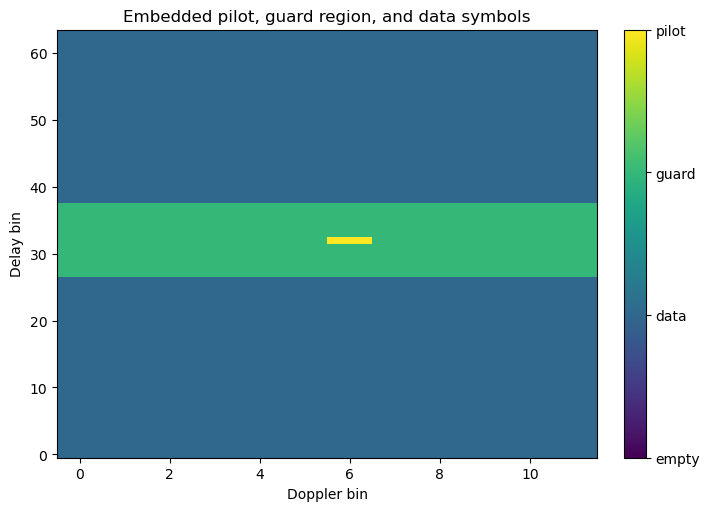

: 

: 

: 

: 

: 

In [ ]:
# Manual resource-grid structure view using the notebook's DD convention:
# x-axis = Doppler bin, y-axis = delay bin.

# structure uses the notebook plotting convention [delay, Doppler].
structure = np.zeros((M, N), dtype=int)  # [delay, Doppler]

# Sionna pilot mask after indexing has shape [Doppler, delay].
mask_2d = pilot_pattern.mask.numpy()[0, 0]  # [Doppler, delay]
# Data locations are all resource elements not reserved by the pilot mask.
structure[mask_2d.T == 0] = 1              # data

guard_delay_left = pilot_info["guard_delay_left"]
guard_delay_right = pilot_info["guard_delay_right"]
guard_doppler_left = pilot_info["guard_doppler_left"]
guard_doppler_right = pilot_info["guard_doppler_right"]

# Mark the rectangular guard region around the embedded pilot.
structure[
    guard_delay_left : guard_delay_right + 1,
    guard_doppler_left : guard_doppler_right + 1,
] = 2  # guard

pilot_l = pilot_info["pilot_delay_idx"]
pilot_k = pilot_info["pilot_doppler_idx"]
# Mark the single nonzero embedded pilot.
structure[pilot_l, pilot_k] = 3

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
im = ax.imshow(
    structure,
    aspect="auto",
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=3,
)
ax.set_title("Embedded pilot, guard region, and data symbols")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
cbar = fig.colorbar(im, ax=ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["empty", "data", "guard", "pilot"])
plt.show()

## 3. Transmit One OTFS Frame using Sionna Mapping and OTFS Precoding

Standard pipeline from Notebook 3: `BinarySource`, `Mapper`, `ResourceGridMapper`, `OTFSModulator`, `OFDMModulator`.

The transmitted delay-Doppler grid `x_dd` is shown with the pilot region visible at the configured location. After OTFS precoding (ISFFT) and OFDM modulation, the serialized waveform `x_time` is ready for transmission.

In [ ]:
# BinarySource, Mapper, and Demapper are native Sionna blocks.
binary_source = BinarySource(seed=2)
mapper = Mapper("qam", NUM_BITS_PER_SYMBOL)
demapper = Demapper("app", "qam", NUM_BITS_PER_SYMBOL)

num_data_bits = int(rg.num_data_symbols * NUM_BITS_PER_SYMBOL)
bits = binary_source([BATCH_SIZE, NUM_TX, NUM_STREAMS_PER_TX, num_data_bits])
x_data = mapper(bits)

# This is the delay-Doppler grid for OTFS.
# Arrange QAM symbols on the OTFS delay-Doppler grid.
# The mapper automatically skips pilot and guard resource elements.
x_dd = rg_mapper(x_data)  # [batch, tx, stream, Doppler, delay]

# Custom OTFS transforms: DD -> TF at the transmitter and TF -> DD at the receiver.
otfs_modulator = OTFSModulator()
otfs_demodulator = OTFSDemodulator()

# Native Sionna OFDM blocks handle CP insertion/removal and FFT/IFFT operations.
ofdm_modulator = OFDMModulator(cyclic_prefix_length=CP_LEN)
ofdm_demodulator_with_cp = OFDMDemodulator(
    fft_size=M,
    l_min=CHANNEL_L_MIN,
    cyclic_prefix_length=CP_LEN,
)
# Use this demodulator after time-domain LMMSE because the equalizer output is CP-free.
ofdm_demodulator_no_cp = OFDMDemodulator(
    fft_size=M,
    l_min=CHANNEL_L_MIN,
    cyclic_prefix_length=0,
)

# OTFS precoding: delay-Doppler -> time-frequency.
x_tf = otfs_modulator(x_dd)
# OFDM modulation: time-frequency -> serialized time-domain waveform with CP.
x_time = ofdm_modulator(x_tf)

print("x_data shape:", x_data.shape)
print("x_dd shape:  ", x_dd.shape)
print("x_tf shape:  ", x_tf.shape)
print("x_time shape:", x_time.shape)

x_data shape: (1, 1, 1, 636)
x_dd shape:   (1, 1, 1, 12, 64)
x_tf shape:   (1, 1, 1, 12, 64)
x_time shape: (1, 1, 1, 888)


: 

: 

: 

: 

: 

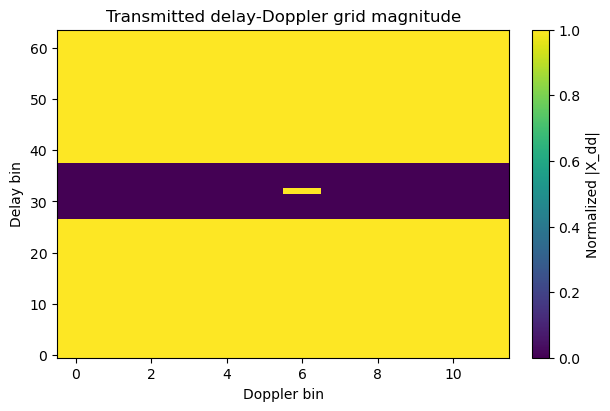

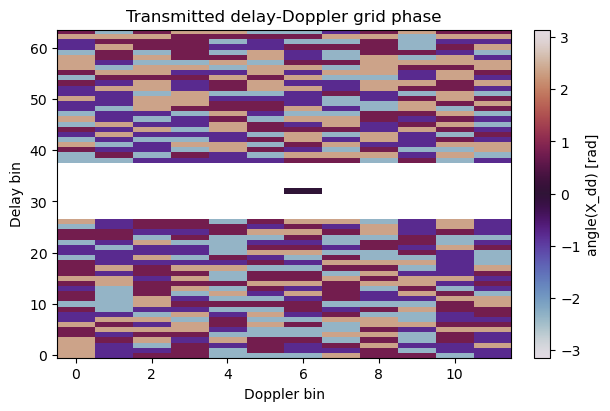

: 

: 

: 

: 

: 

In [ ]:
# Remove batch/tx/stream axes; the remaining grid is [Doppler, delay].
Xdd = x_dd.numpy()[0, 0, 0]  # [Doppler, delay]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
shown = np.abs(Xdd).T
shown = shown / (np.max(shown) + 1e-12)
im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Transmitted delay-Doppler grid magnitude")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="Normalized |X_dd|")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
phase = masked_phase(Xdd).T
im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
ax.set_title("Transmitted delay-Doppler grid phase")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="angle(X_dd) [rad]")
plt.show()

## 4. Channel Cases

Four synthetic channels are defined to expose different aspects of the estimator's behaviour:

| Case | Delay | Doppler | Estimation difficulty |
|---|---|---|---|
| Static multipath | $\ell_i \neq 0$ | $\kappa_i = 0$ | Baseline; integer taps only |
| Integer Doppler | $\ell_i \neq 0$ | $\kappa_i \in \mathbb{Z} \setminus \{0\}$ | Integer taps; estimator should be near-exact |
| Sparse DD | $\ell_i \neq 0$ | $\kappa_i \in \mathbb{Z}$ (multiple) | Multiple paths at integer positions |
| Fractional Doppler | $\ell_i \neq 0$ | $\kappa_i \notin \mathbb{Z}$ | Off-grid; integer-tap model introduces mismatch |

All cases use maximum delay tap max$(\ell_i) \leq$ `CHANNEL_L_MAX`, so the equalizer models the full delay spread. The fractional Doppler case is the stress test: the estimator detects peaks at integer bins while the true paths sit between bins, introducing a systematic error that is independent of SNR.

In [ ]:
# Small synthetic channels chosen to isolate specific delay-Doppler effects.
channel_cases = {
    "Static multipath": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j], dtype=np.complex64),
        "l_i": np.array([0, 2], dtype=np.int32),
        "k_i": np.array([0.0, 0.0], dtype=np.float32),
    },
    "Integer Doppler": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j], dtype=np.complex64),
        "l_i": np.array([0, 2], dtype=np.int32),
        "k_i": np.array([0.0, 1.0], dtype=np.float32),
    },
    "Sparse DD": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j, 0.3 - 0.2j], dtype=np.complex64),
        "l_i": np.array([0, 2, 3], dtype=np.int32),
        "k_i": np.array([0.0, 1.0, -1.0], dtype=np.float32),
    },
    "Fractional Doppler": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j, 0.3 - 0.2j], dtype=np.complex64),
        "l_i": np.array([0, 2, 3], dtype=np.int32),
        "k_i": np.array([0.0, 1.5, -0.7], dtype=np.float32),
    },
}

channel_data = {}
num_time_samples = int(rg.num_time_samples)
# Sionna CIR generation needs the number of channel samples accessed by ApplyTimeChannel.
num_time_steps = get_required_num_cir_time_steps(
    num_time_samples=num_time_samples,
    l_min=CHANNEL_L_MIN,
    l_max=CHANNEL_L_MAX,
)

# Time-domain channel application using generated CIR tensors a and tau.
channel = ApplyCIRTimeChannel(
    bandwidth=rg.bandwidth,
    l_min=CHANNEL_L_MIN,
    l_max=CHANNEL_L_MAX,
    normalize=CHANNEL_NORMALIZE,
)

awgn = AWGN()
# Convert Eb/N0 into the noise variance used by AWGN, the estimator, and LMMSE.
no = ebnodb2no(
    EBNO_DB,
    NUM_BITS_PER_SYMBOL,
    CODERATE_FOR_NO,
    rg,
) * NUM_BITS_PER_SYMBOL

print("Noise variance:", no.numpy() if hasattr(no, "numpy") else no)
print("CIR time steps:", num_time_steps)

for name, params in channel_cases.items():
    # Convert each DD-path model into Sionna-compatible CIR tensors.
    generator = DDPathCIRGenerator(
            g_i=params["g_i"],
            l_i=params["l_i"],
            k_i=params["k_i"],
        )

    a, tau = generator(
        batch_size=BATCH_SIZE,
        num_time_steps=num_time_steps,
        bandwidth=rg.bandwidth,
    )

    y_time, h_time = channel(x_time, a, tau)
    y_time_noisy = awgn(y_time, no)

    y_tf_no_eq = ofdm_demodulator_with_cp(y_time_noisy)
    y_dd_no_eq = otfs_demodulator(y_tf_no_eq)
    x_hat_no_eq = rg_demapper(y_dd_no_eq)

    # Extract the true delay-time channel representation used by BlockLMMSEEqualizer.
    gs_true = h_time_to_gs(h_time, num_time_samples)

    channel_data[name] = {
        **params,
        "a": a,
        "tau": tau,
        "h_time": h_time,
        "y_time": y_time,
        "y_time_noisy": y_time_noisy,
        "y_tf_no_eq": y_tf_no_eq,
        "y_dd_no_eq": y_dd_no_eq,
        "x_hat_no_eq": x_hat_no_eq,
        "gs_true": gs_true,
    }

    print(f"{name:20s}  g_i={params['g_i']}  l_i={params['l_i']}  k_i={params['k_i']}")

Noise variance: 0.0013962263
CIR time steps: 893
Static multipath      g_i=[1.  +0.j   0.55+0.25j]  l_i=[0 2]  k_i=[0. 0.]
Integer Doppler       g_i=[1.  +0.j   0.55+0.25j]  l_i=[0 2]  k_i=[0. 1.]
Sparse DD             g_i=[1.  +0.j   0.55+0.25j 0.3 -0.2j ]  l_i=[0 2 3]  k_i=[ 0.  1. -1.]
Fractional Doppler    g_i=[1.  +0.j   0.55+0.25j 0.3 -0.2j ]  l_i=[0 2 3]  k_i=[ 0.   1.5 -0.7]


: 

: 

: 

: 

: 

## 5. Why Equalization is Needed

Constellations of the received data symbols before any equalization, at the configured Eb/N0.

Even the static multipath channel -- ideal for OFDM -- produces badly distorted constellations because the QAM symbols are scaled and rotated by the frequency-selective channel gain. Without equalization a symbol demapper would make many errors.

The Doppler channels produce additional spreading because ICI adds interference that differs for each received symbol. The fractional Doppler case shows the most severe distortion, with the QAM clusters merging into a diffuse cloud.

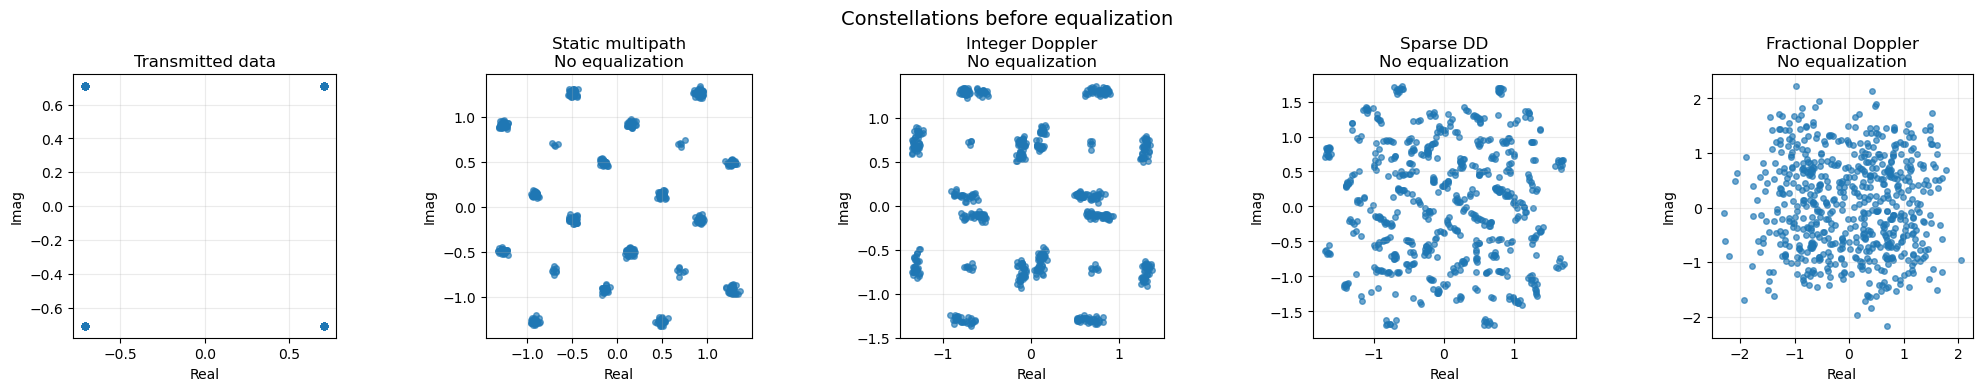

: 

: 

: 

: 

: 

In [ ]:
x_symbols = x_data.numpy()[0, 0, 0].reshape(-1)

fig, axes = plt.subplots(
    1,
    len(channel_data) + 1,
    figsize=(4.1 * (len(channel_data) + 1), 3.8),
    constrained_layout=True,
)

axes[0].scatter(np.real(x_symbols), np.imag(x_symbols), s=20, alpha=0.8)
axes[0].set_title("Transmitted data")
axes[0].set_xlabel("Real")
axes[0].set_ylabel("Imag")
axes[0].grid(True, alpha=0.25)
axes[0].set_aspect("equal", adjustable="box")

for ax, (name, data) in zip(axes[1:], channel_data.items()):
    # Demapped data symbols obtained without any equalization.
    y_no_eq = data["x_hat_no_eq"].numpy()[0, 0, 0].reshape(-1)
    ax.scatter(np.real(y_no_eq), np.imag(y_no_eq), s=16, alpha=0.65)
    ax.set_title(f"{name}\nNo equalization")
    ax.set_xlabel("Real")
    ax.set_ylabel("Imag")
    ax.grid(True, alpha=0.25)
    ax.set_aspect("equal", adjustable="box")

fig.suptitle("Constellations before equalization", fontsize=14)
plt.show()

## 6. Delay-Time Channel Representation used by the Equalizer

`BlockLMMSEEqualizer` works with the delay-time channel `gs[l, q]`, not with the raw CIR tensor `(a, tau)` or the delay-Doppler path list `(g_i, l_i, k_i)`.

`gs[l, q]` is the discrete time-domain channel impulse response at delay tap $\ell$ and time index $q$. It is the transpose of `h_time`:

$$\text{gs}[\ell, q] = h[q, \ell]$$

For the equalizer, the key property of `gs` is that the effective $M \times M$ channel matrix for block $n$ can be read directly from `gs` evaluated at the CP-shifted time indices of that block. `h_time_to_gs` from `channel_utils` handles the indexing conversion from Sionna's `h_time` tensor to the `[delay, time]` array that `BlockLMMSEEqualizer` expects.

The magnitude plots show active delay taps as bright horizontal bands. The phase plots show the Doppler-induced phase ramp evolving across the frame duration for the Doppler channel cases.

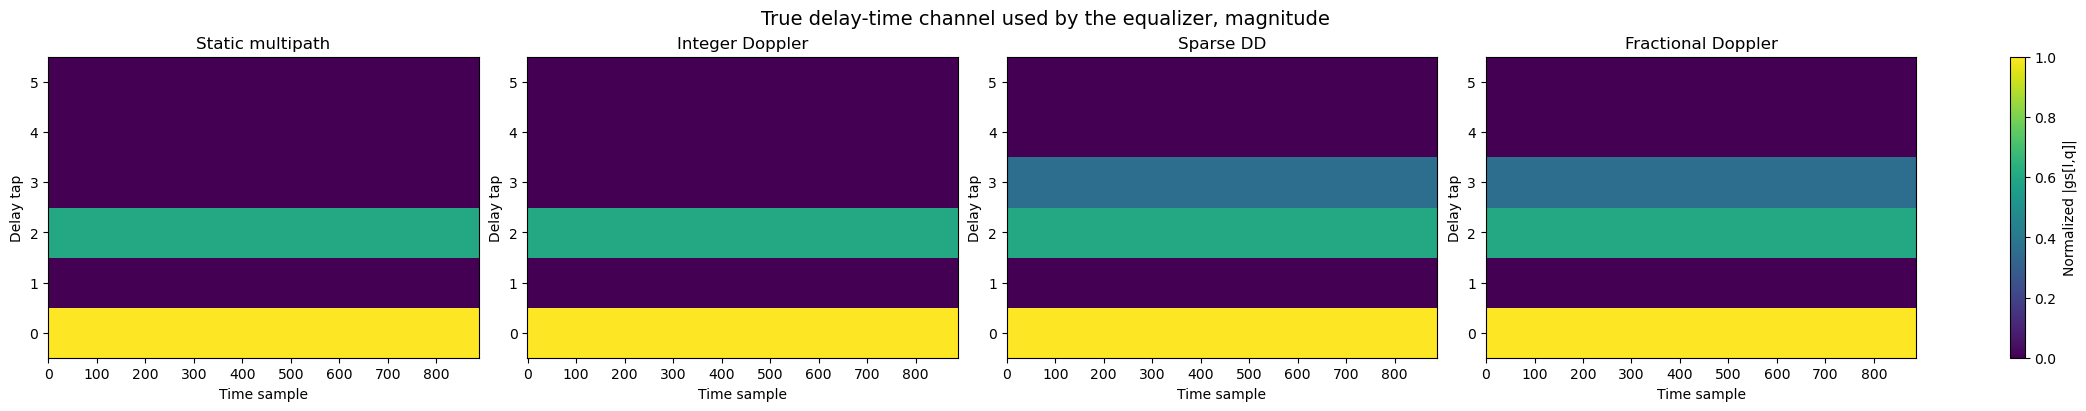

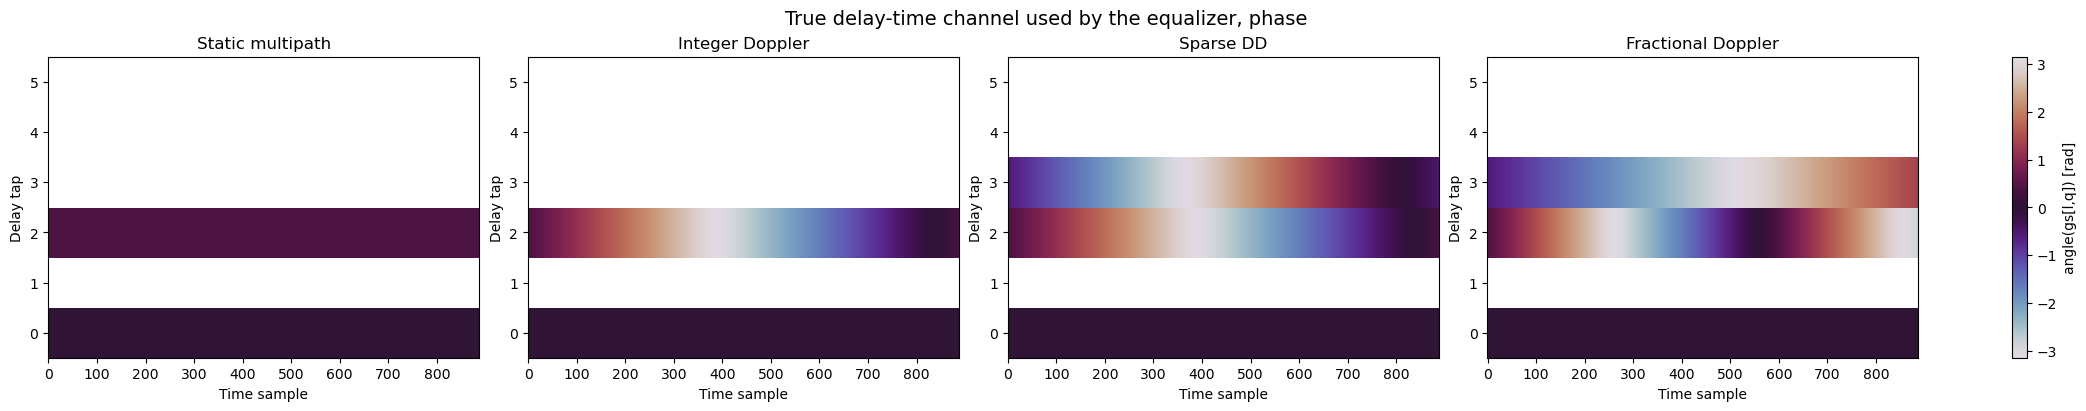

: 

: 

: 

: 

: 

In [ ]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    # gs is the delay-time channel representation used internally by BlockLMMSEEqualizer.
    # Shape convention: [delay, time].
    gs = data["gs_true"].numpy()  # [delay, time]
    shown = np.abs(gs)
    shown = shown / (np.max(shown) + 1e-12)

    im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized |gs[l,q]|")
fig.suptitle("True delay-time channel used by the equalizer, magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    gs = data["gs_true"].numpy()
    phase = masked_phase(gs)

    im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(gs[l,q]) [rad]")
fig.suptitle("True delay-time channel used by the equalizer, phase", fontsize=14)
plt.show()

## 7. Actual Block Matrices inside `BlockLMMSEEqualizer`

`build_block_channel_matrices` constructs the explicit $M \times M$ per-block matrices $G_n$ from `gs`. Entry $G_n[m_\text{rx}, m_\text{tx}]$ is non-zero only when $0 \leq m_\text{rx} - m_\text{tx} \leq L_\text{max}$, giving a lower-banded structure with bandwidth `CHANNEL_L_MAX + 1`.

Representative blocks from the beginning, middle, and end of the frame are shown for each channel case. Two structural observations:

**Static multipath:** the matrix is nearly circulant -- the values along each sub-diagonal are approximately constant. This is the condition under which the DFT diagonalization from Notebook 2 holds and single-tap equalization would work well.

**Doppler channels:** the values along each sub-diagonal change from row to row as the Doppler-induced phase ramp evolves within the block. The deviation from circulant structure grows with the Doppler tap magnitude and with the block length $M$. Blocks at different positions in the frame also differ slightly from one another because `gs` is evaluated at the time index of each block separately.

In [ ]:
# Custom block-wise time-domain LMMSE equalizer.
# It operates directly on the delay-time channel gs.
block_lmmse = BlockLMMSEEqualizer(
    num_blocks=N,
    fft_size=M,
    cyclic_prefix_length=CP_LEN,
)

REPRESENTATIVE_BLOCKS = [0, N // 2, N - 1]

for name, data in channel_data.items():
    # Build the effective per-OFDM-symbol channel matrices used by the equalizer.
    G_blocks = block_lmmse.build_block_channel_matrices(data["gs_true"])
    data["G_blocks_true"] = G_blocks
    print(name, "G_blocks shape:", G_blocks.shape)

Static multipath G_blocks shape: (12, 64, 64)
Integer Doppler G_blocks shape: (12, 64, 64)
Sparse DD G_blocks shape: (12, 64, 64)
Fractional Doppler G_blocks shape: (12, 64, 64)


: 

: 

: 

: 

: 

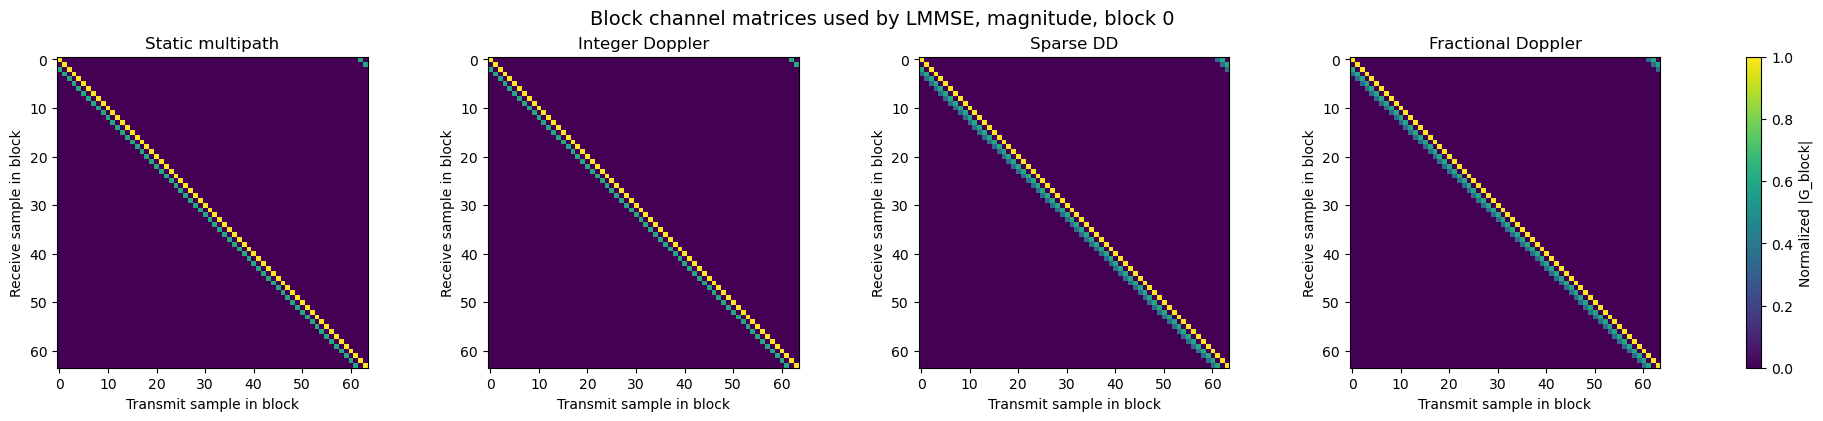

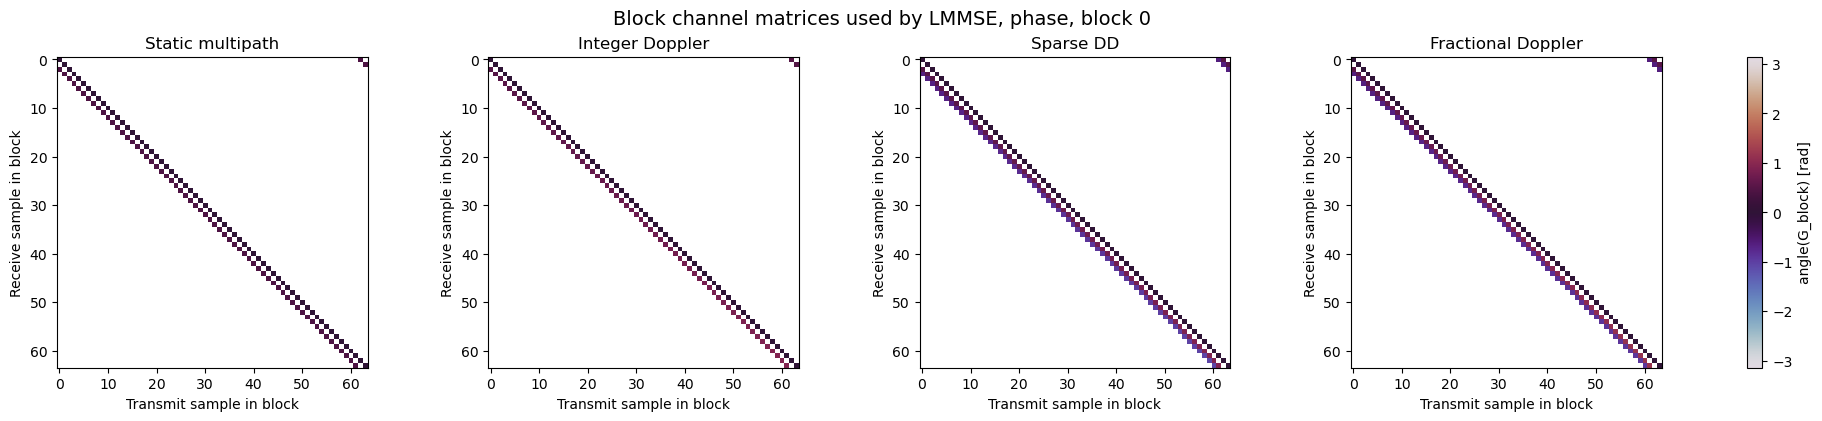

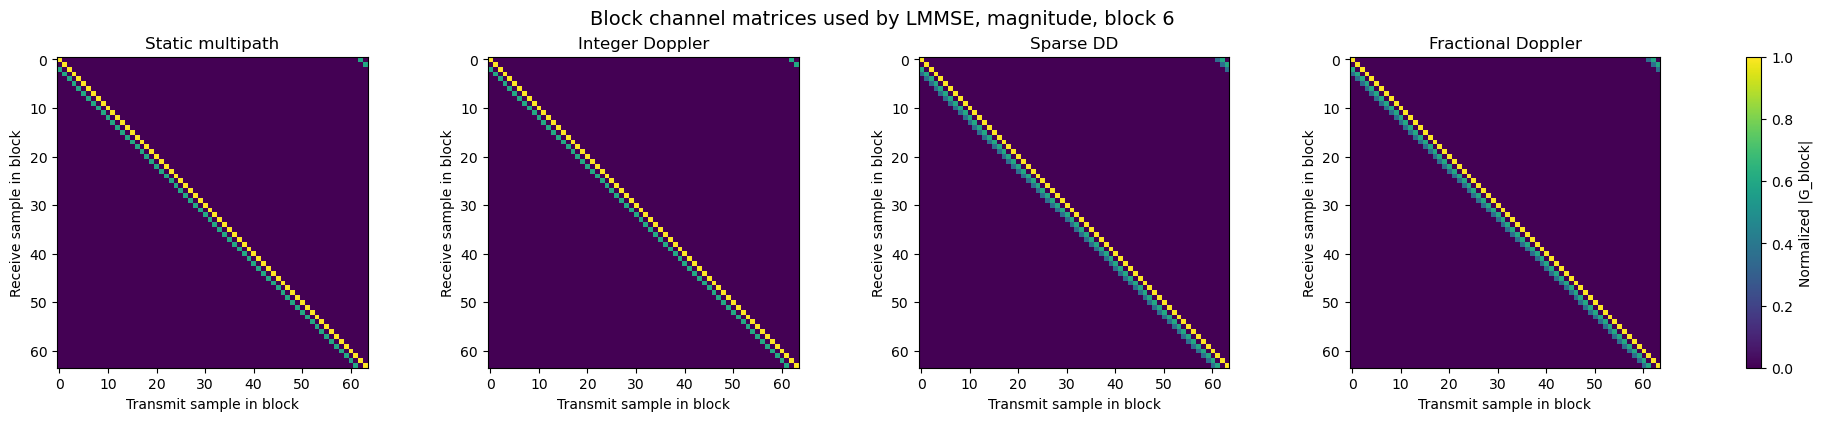

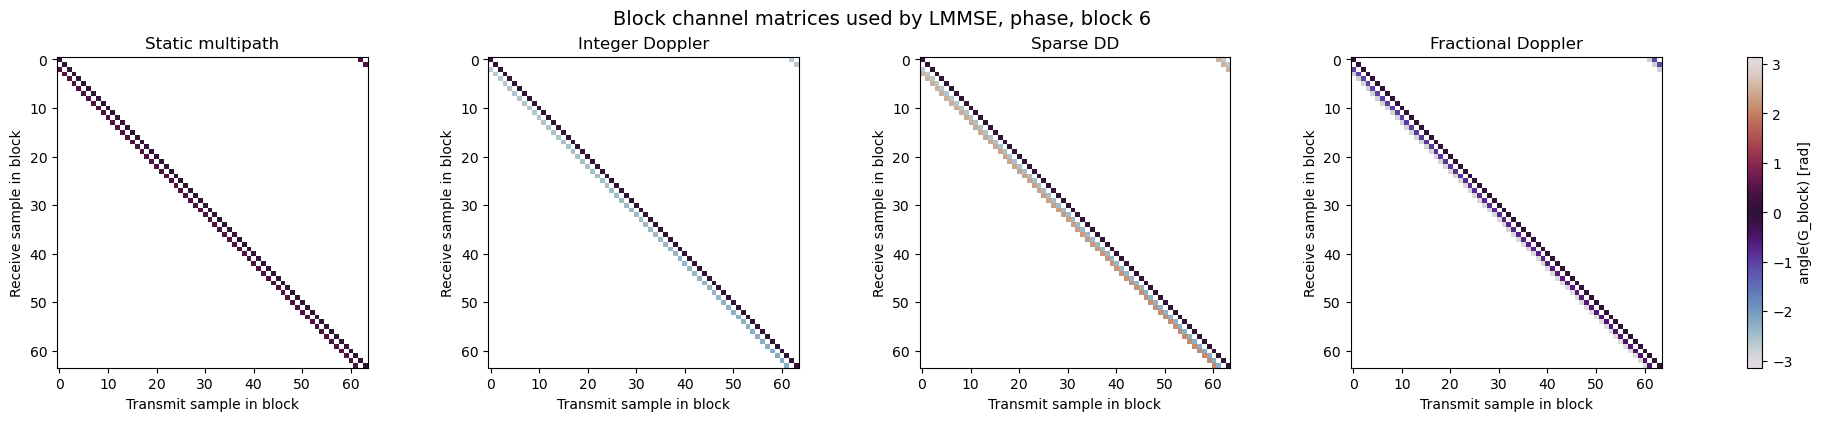

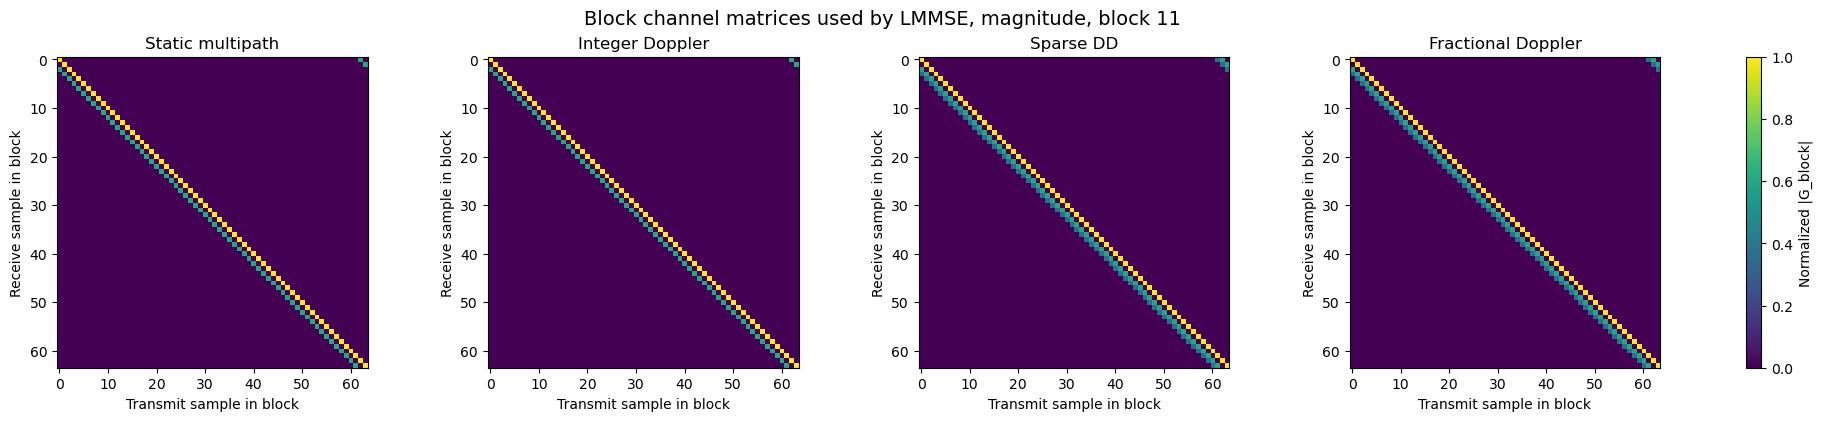

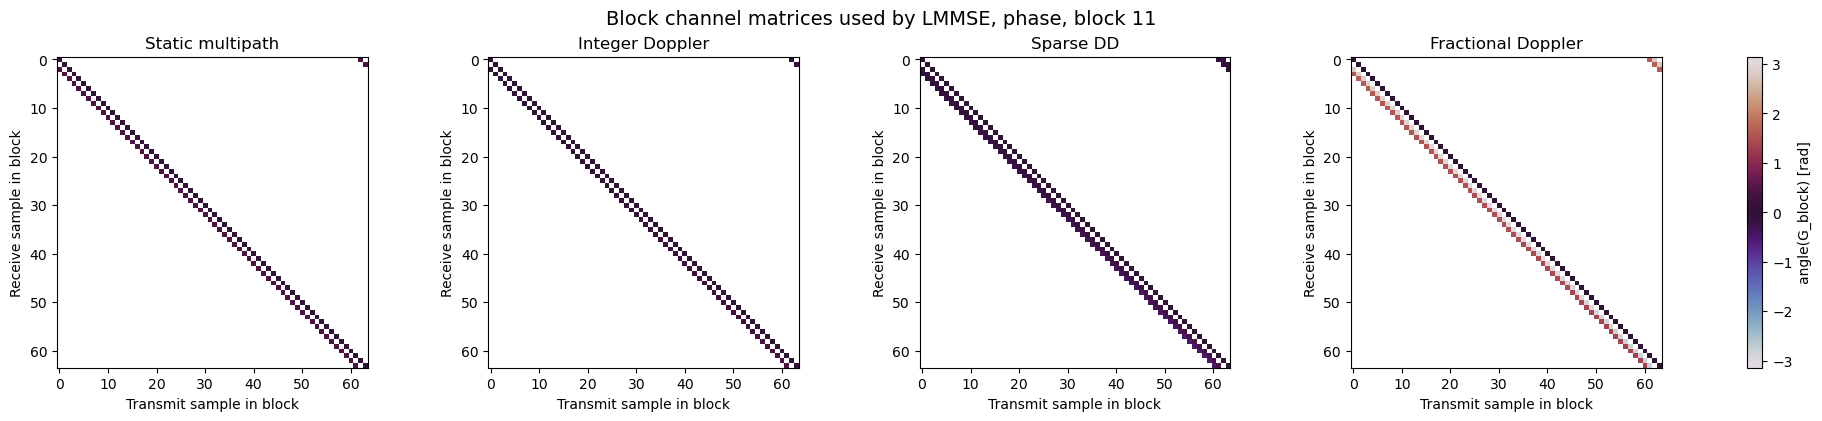

: 

: 

: 

: 

: 

In [ ]:
for block_index in REPRESENTATIVE_BLOCKS:
    fig, axes = plt.subplots(1, len(channel_data), figsize=(4.7 * len(channel_data), 4.1), constrained_layout=True)
    if len(channel_data) == 1:
        axes = [axes]

    for ax, (name, data) in zip(axes, channel_data.items()):
        G = data["G_blocks_true"][block_index].numpy()
        shown = np.abs(G)
        shown = shown / (np.max(shown) + 1e-12)

        im = ax.imshow(shown, aspect="equal", origin="upper", cmap="viridis", vmin=0, vmax=1)
        ax.set_title(name)
        ax.set_xlabel("Transmit sample in block")
        ax.set_ylabel("Receive sample in block")

    fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized |G_block|")
    fig.suptitle(f"Block channel matrices used by LMMSE, magnitude, block {block_index}", fontsize=14)
    plt.show()

    fig, axes = plt.subplots(1, len(channel_data), figsize=(4.7 * len(channel_data), 4.1), constrained_layout=True)
    if len(channel_data) == 1:
        axes = [axes]

    for ax, (name, data) in zip(axes, channel_data.items()):
        G = data["G_blocks_true"][block_index].numpy()
        phase = masked_phase(G)

        im = ax.imshow(phase, aspect="equal", origin="upper", cmap="twilight", vmin=-np.pi, vmax=np.pi)
        ax.set_title(name)
        ax.set_xlabel("Transmit sample in block")
        ax.set_ylabel("Receive sample in block")

    fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(G_block) [rad]")
    fig.suptitle(f"Block channel matrices used by LMMSE, phase, block {block_index}", fontsize=14)
    plt.show()

## 8. Perfect-CSI Block LMMSE Equalization

`BlockLMMSEEqualizer` applies the MMSE filter independently for each block:

$$\hat{s}_n = \left(G_n^H G_n + \sigma_w^2 I_M\right)^{-1} G_n^H r_n$$

where $r_n$ is the $n$-th received block after CP removal and noise addition, and $G_n$ is the block channel matrix constructed from `gs_true`.

The equalizer output is CP-free, so the subsequent OFDM demodulation step uses the no-CP `OFDMDemodulator` variant.

The two-row constellation comparison shows received symbols before equalization (top) and after perfect-CSI equalization (bottom). For all four channel cases the QAM clusters are clearly recovered after equalization. The residual spread within each cluster reflects the noise at the configured Eb/N0. The fractional Doppler case shows slightly wider clusters because the block LMMSE constructs integer-tap matrices that cannot exactly represent the true fractional-tap channel, even with perfect CSI.

In [ ]:
for name, data in channel_data.items():
    # Equalize using the true channel gs.
    y_time_lmmse = block_lmmse(
        data["y_time_noisy"],
        data["gs_true"],
        no,
    )

    # The equalizer output is CP-free, so use the no-CP OFDM demodulator.
    y_tf_lmmse = ofdm_demodulator_no_cp(y_time_lmmse)
    y_dd_lmmse = otfs_demodulator(y_tf_lmmse)
    # Recover only the transmitted data symbols; pilot and guard positions are discarded.
    x_hat_lmmse = rg_demapper(y_dd_lmmse)

    data["y_time_lmmse"] = y_time_lmmse
    data["y_tf_lmmse"] = y_tf_lmmse
    data["y_dd_lmmse"] = y_dd_lmmse
    data["x_hat_lmmse"] = x_hat_lmmse

print("Perfect-CSI LMMSE equalization completed.")

Perfect-CSI LMMSE equalization completed.


: 

: 

: 

: 

: 

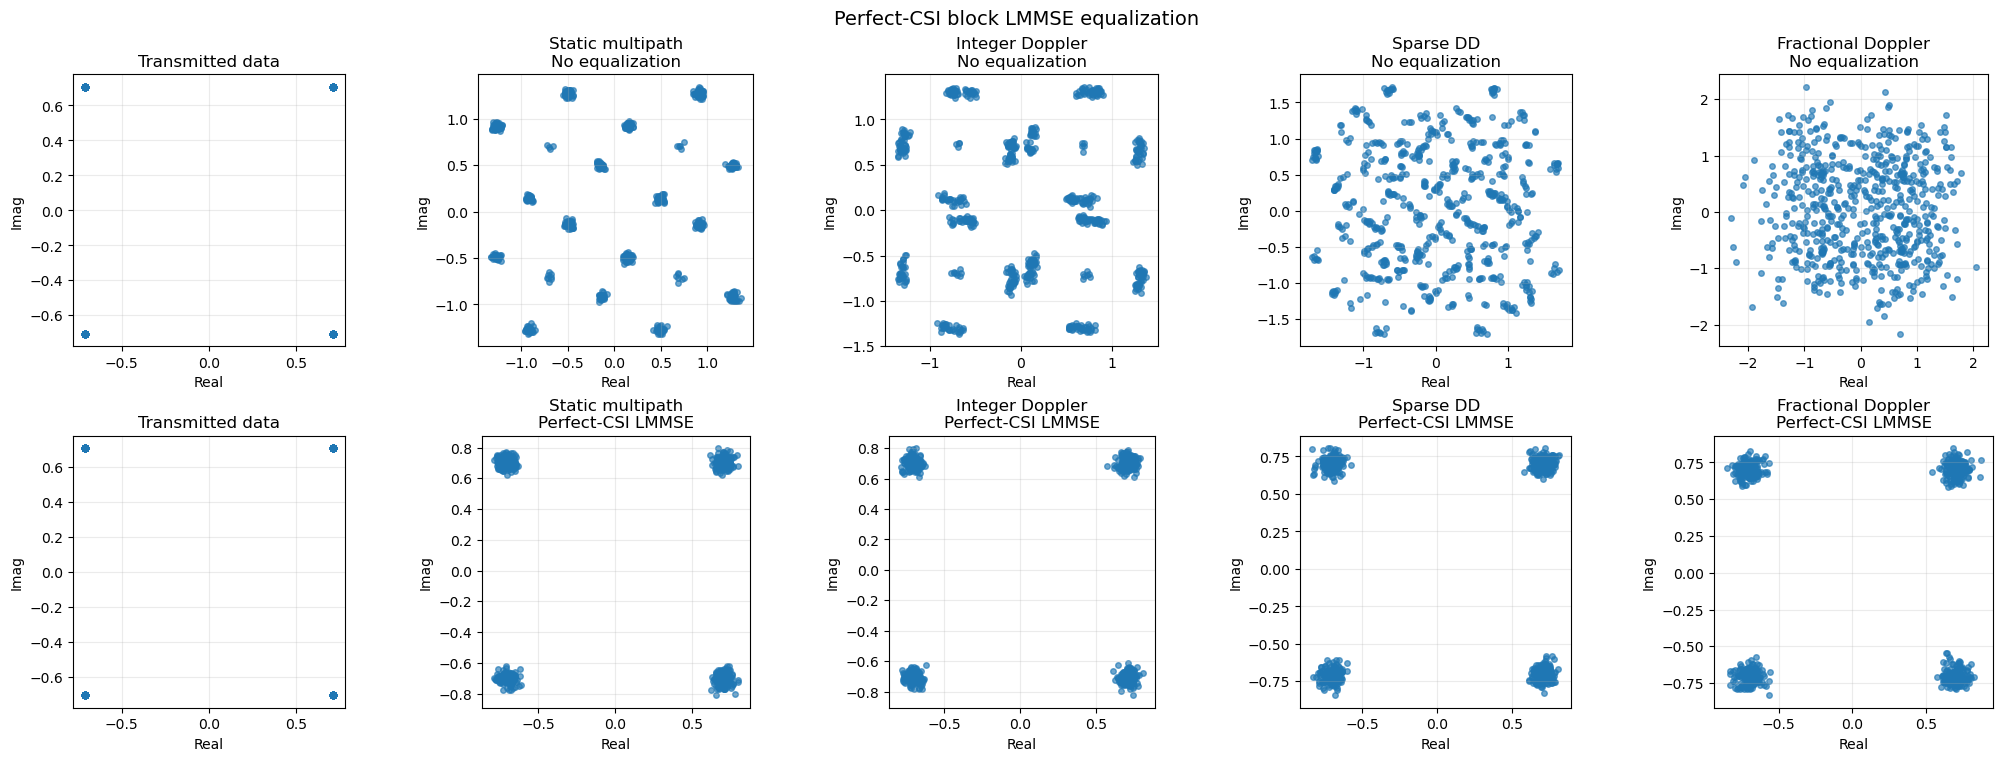

: 

: 

: 

: 

: 

In [ ]:
fig, axes = plt.subplots(
    2,
    len(channel_data) + 1,
    figsize=(4.1 * (len(channel_data) + 1), 7.5),
    constrained_layout=True,
)

for row in range(2):
    axes[row, 0].scatter(np.real(x_symbols), np.imag(x_symbols), s=20, alpha=0.8)
    axes[row, 0].set_title("Transmitted data")
    axes[row, 0].set_xlabel("Real")
    axes[row, 0].set_ylabel("Imag")
    axes[row, 0].grid(True, alpha=0.25)
    axes[row, 0].set_aspect("equal", adjustable="box")

for col, (name, data) in enumerate(channel_data.items(), start=1):
    y_no_eq = data["x_hat_no_eq"].numpy()[0, 0, 0].reshape(-1)
    y_lmmse = data["x_hat_lmmse"].numpy()[0, 0, 0].reshape(-1)

    axes[0, col].scatter(np.real(y_no_eq), np.imag(y_no_eq), s=16, alpha=0.65)
    axes[0, col].set_title(f"{name}\nNo equalization")
    axes[0, col].set_xlabel("Real")
    axes[0, col].set_ylabel("Imag")
    axes[0, col].grid(True, alpha=0.25)
    axes[0, col].set_aspect("equal", adjustable="box")

    axes[1, col].scatter(np.real(y_lmmse), np.imag(y_lmmse), s=16, alpha=0.65)
    axes[1, col].set_title(f"{name}\nPerfect-CSI LMMSE")
    axes[1, col].set_xlabel("Real")
    axes[1, col].set_ylabel("Imag")
    axes[1, col].grid(True, alpha=0.25)
    axes[1, col].set_aspect("equal", adjustable="box")

fig.suptitle("Perfect-CSI block LMMSE equalization", fontsize=14)
plt.show()

## 9. Received DD Grids before and after Perfect-CSI Equalization

The delay-Doppler grid view of the same equalization step, zoomed to the region around the pilot.

Before equalization the pilot region shows the channel response: each propagation path shifts the pilot's energy to a different $(\ell, k)$ offset relative to the pilot location. The offset pattern directly encodes the channel's delay-Doppler structure.

After equalization the data symbols in the surrounding region recover their intended amplitude and the pilot response contracts back towards its transmitted position. The equalization operates on the full waveform and corrects data and pilot regions uniformly.

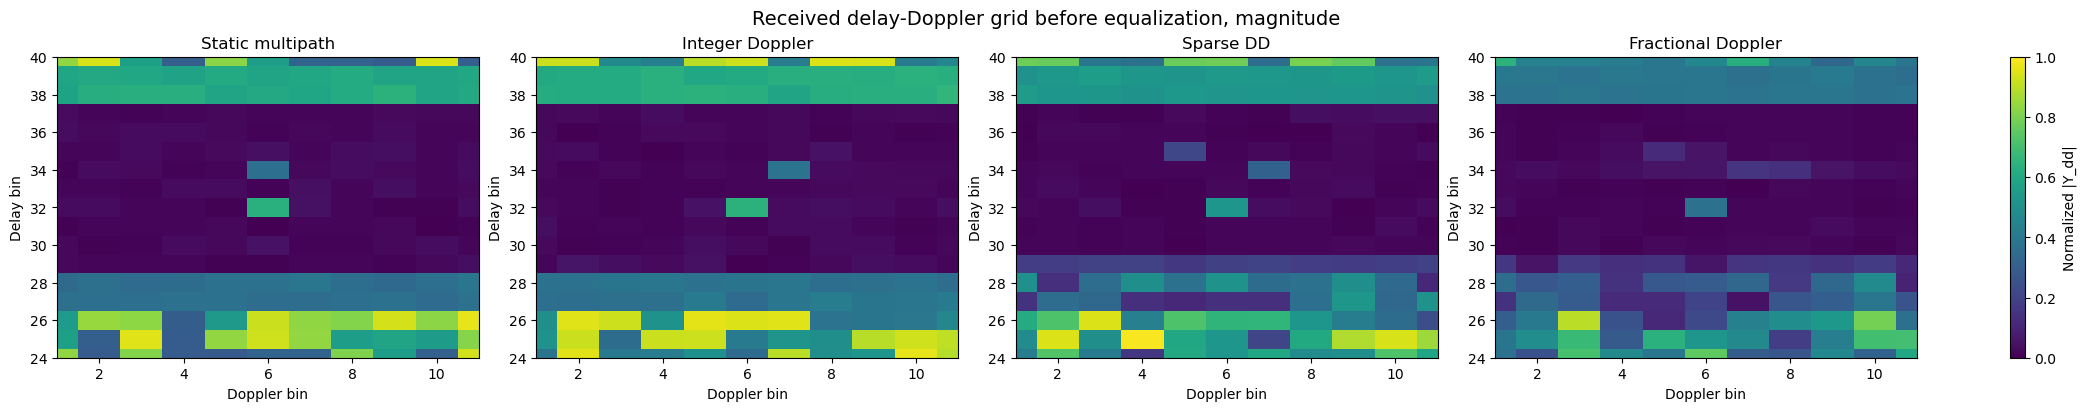

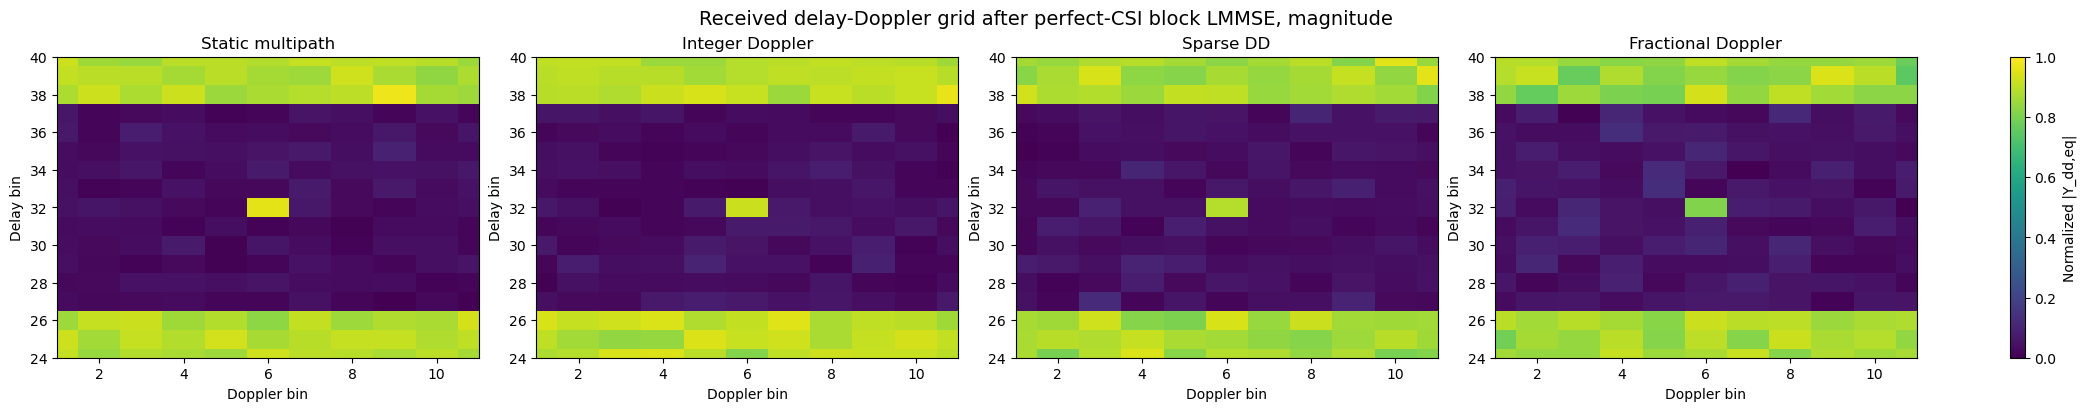

: 

: 

: 

: 

: 

In [ ]:
for key, title, label in [
    ("y_dd_no_eq", "Received delay-Doppler grid before equalization", "Normalized |Y_dd|"),
    ("y_dd_lmmse", "Received delay-Doppler grid after perfect-CSI block LMMSE", "Normalized |Y_dd,eq|"),
]:
    fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
    if len(channel_data) == 1:
        axes = [axes]

    for ax, (name, data) in zip(axes, channel_data.items()):
        Ydd = data[key].numpy()[0, 0, 0]  # [Doppler, delay]
        shown = np.abs(Ydd).T
        shown = shown / (np.max(shown) + 1e-12)
        im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
        doppler_margin = 5
        delay_margin = 8

        ax.set_xlim(
            pilot_k - doppler_margin,
            pilot_k + doppler_margin,
        )

        ax.set_ylim(
            pilot_l - delay_margin,
            pilot_l + delay_margin,
        )
        ax.set_title(name)
        ax.set_xlabel("Doppler bin")
        ax.set_ylabel("Delay bin")

    fig.colorbar(im, ax=np.ravel(axes).tolist(), label=label)
    fig.suptitle(title + ", magnitude", fontsize=14)
    plt.show()


## 10. Pilot Response in the Received Delay-Doppler Grid

A pilot-only frame (all zeros except for the single pilot symbol at its configured position) is transmitted to isolate the channel response cleanly from data interference.

The received pilot responses show the channel's delay-Doppler spreading function directly. For each channel case, the bright spots in the received grid correspond to the propagation paths, shifted from the pilot position by their respective $(\ell_i, \kappa_i)$ offsets:

- **Static multipath:** spots at delay offsets $\ell_i$, all at the pilot's Doppler bin.
- **Integer Doppler:** spots at both delay and Doppler offsets matching the integer path parameters exactly.
- **Sparse DD:** three spots at their respective $(\ell_i, \kappa_i)$ positions.
- **Fractional Doppler:** the spots are smeared in the Doppler direction due to sinc leakage. Each fractional-Doppler path spreads its energy across adjacent bins rather than concentrating in one.

The white grid lines mark the pilot's delay and Doppler position. The estimator in Section 11 searches for peaks above a noise threshold within the guard region and declares each peak a propagation path.

In [ ]:
# Pilot-only frame to isolate the channel response around the embedded pilot.
# Build a frame containing only the embedded pilot.
# This isolates the channel response from data-symbol interference.
x_dd_pilot_np = np.zeros((BATCH_SIZE, NUM_TX, NUM_STREAMS_PER_TX, N, M), dtype=np.complex64)
x_dd_pilot_np[0, 0, 0, pilot_k, pilot_l] = PILOT_SYMBOL
x_dd_pilot = tf.constant(x_dd_pilot_np, dtype=tf.complex64)

x_tf_pilot = otfs_modulator(x_dd_pilot)
x_time_pilot = ofdm_modulator(x_tf_pilot)

for name, data in channel_data.items():
    y_time_pilot, h_time_pilot = channel(x_time_pilot, data["a"], data["tau"])
    y_time_pilot_noisy = awgn(y_time_pilot, no)
    y_tf_pilot = ofdm_demodulator_with_cp(y_time_pilot_noisy)
    # Received pilot response in the delay-Doppler domain.
    y_dd_pilot = otfs_demodulator(y_tf_pilot)

    data["x_dd_pilot"] = x_dd_pilot
    data["y_dd_pilot"] = y_dd_pilot

print("Pilot-only transmissions completed.")

Pilot-only transmissions completed.


: 

: 

: 

: 

: 

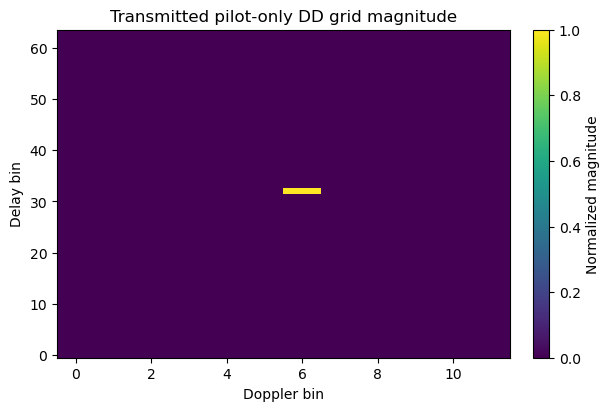

: 

: 

: 

: 

: 

In [ ]:
Xpilot = x_dd_pilot.numpy()[0, 0, 0]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
shown = np.abs(Xpilot).T
shown = shown / (np.max(shown) + 1e-12)
im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Transmitted pilot-only DD grid magnitude")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="Normalized magnitude")
plt.show()

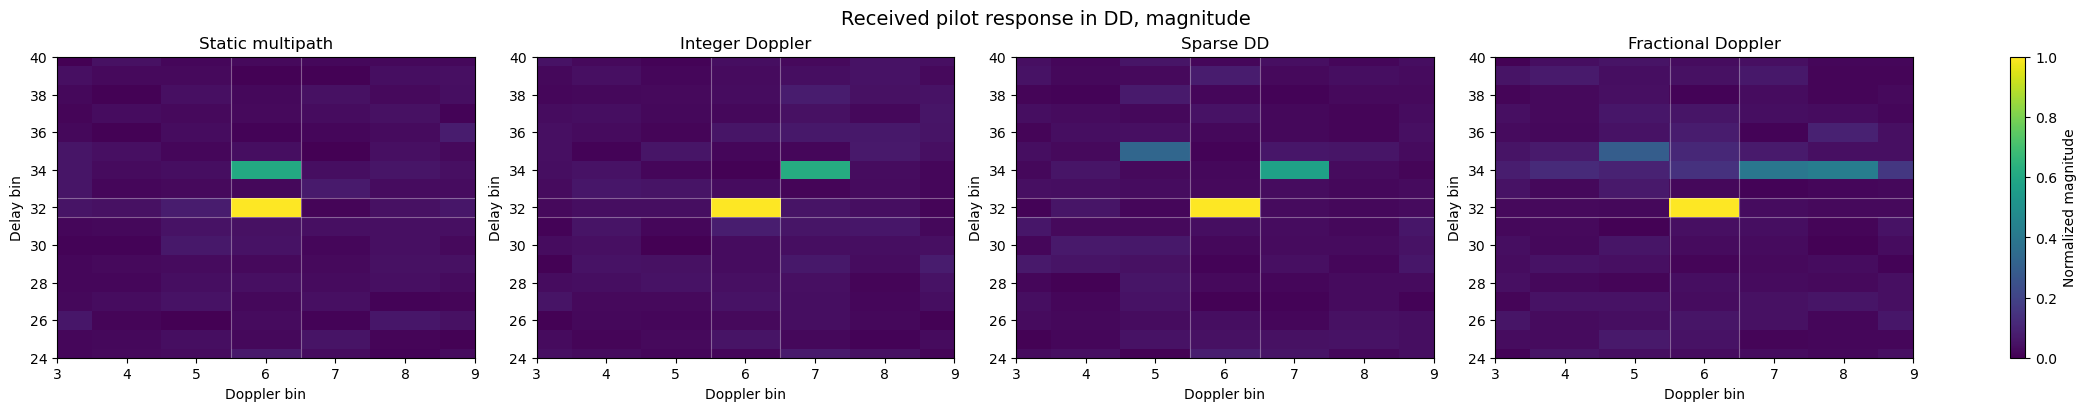

: 

: 

: 

: 

: 

In [ ]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    Y = data["y_dd_pilot"].numpy()[0, 0, 0]
    shown = np.abs(Y).T
    shown = shown / (np.max(shown) + 1e-12)
    im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    doppler_margin = 3
    delay_margin = 8

    ax.set_xlim(
        pilot_k - doppler_margin,
        pilot_k + doppler_margin,
    )

    ax.set_ylim(
        pilot_l - delay_margin,
        pilot_l + delay_margin,
    )
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

    ax.axvline(pilot_k - 0.5, color="white", linewidth=0.8, alpha=0.35)
    ax.axvline(pilot_k + 0.5, color="white", linewidth=0.8, alpha=0.35)
    ax.axhline(pilot_l - 0.5, color="white", linewidth=0.8, alpha=0.35)
    ax.axhline(pilot_l + 0.5, color="white", linewidth=0.8, alpha=0.35)

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized magnitude")
fig.suptitle("Received pilot response in DD, magnitude", fontsize=14)
plt.show()

## 11. Threshold-Based Path Detection

`EmbeddedPilotChannelEstimator` compares each received pilot-region sample to a threshold:

$$\text{detected if } |Y_\text{dd}[\ell_\text{pilot} + \ell,\; k_\text{pilot} + k]| \geq \text{threshold\_factor} \cdot \sigma_w$$

where $\sigma_w$ is the noise standard deviation inferred from the noise variance argument.

The printed estimates at `DEFAULT_THRESHOLD_FACTOR` show the detected path parameters $(\hat{\ell}_i, \hat{k}_i, \hat{g}_i)$ alongside the true values for each channel case. For integer Doppler channels the delay and Doppler positions are recovered correctly. For fractional Doppler channels the estimator assigns each path to its nearest integer bin, and the gain estimate reflects the sinc sidelobe value at that bin rather than the true complex gain.

The threshold sweep panels show four values of `threshold_factor` side by side for each channel case. Low thresholds detect more paths (including noise peaks shown as false x markers); high thresholds miss real paths. The correct number of paths is recovered in a middle range of threshold values for the integer Doppler cases. For fractional Doppler the sinc leakage means the estimator always makes some integer-tap approximation regardless of threshold.

In [ ]:
# Convenience wrapper for testing different estimator thresholds.
def get_estimator(threshold_factor):
    return EmbeddedPilotChannelEstimator(
        num_ofdm_symbols=N,
        fft_size=M,
        pilot_info=pilot_info,
        threshold_factor=threshold_factor,
        detection_mode="peakfinder",
        fp_min_persistence=0.2,
    )

for name, data in channel_data.items():
    estimator = get_estimator(DEFAULT_THRESHOLD_FACTOR)
    # Detected DD paths:
    # g_hat = estimated path gains, l_hat = delay taps, k_hat = Doppler taps.
    g_hat, l_hat, k_hat, h_dd_hat = estimator(data["y_dd_pilot"], no)

    data["g_hat"] = g_hat
    data["l_hat"] = l_hat
    data["k_hat"] = k_hat
    data["h_dd_hat"] = h_dd_hat

    print("=" * 80)
    print(name)
    print("true g_i:", data["g_i"])
    print("true l_i:", data["l_i"])
    print("true k_i:", data["k_i"])
    print("estimated g_hat:", g_hat.numpy())
    print("estimated l_hat:", l_hat.numpy())
    print("estimated k_hat:", k_hat.numpy())

[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, 14940.53it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135
Static multipath
true g_i: [1.  +0.j   0.55+0.25j]
true l_i: [0 2]
true k_i: [0. 0.]
estimated g_hat: [1.0129234+0.00917831j 0.5607435+0.25560328j]
estimated l_hat: [0 2]
estimated k_hat: [0 0]


30it [00:00, ?it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, 10664.39it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology


   x  y    score
0  0  2  1.02432
2  2  3  0.58666
Integer Doppler
true g_i: [1.  +0.j   0.55+0.25j]
true l_i: [0 2]
true k_i: [0. 1.]
estimated g_hat: [1.0242043+0.01542656j 0.5898596+0.23618181j]
estimated l_hat: [0 2]
estimated k_hat: [0 1]


30it [00:00, 14756.55it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.042415
2  2  3  0.562404
3  3  1  0.311185
Sparse DD
true g_i: [1.  +0.j   0.55+0.25j 0.3 -0.2j ]
true l_i: [0 2 3]
true k_i: [ 0.  1. -1.]
estimated g_hat: [1.042357  -0.01102645j 0.53669655+0.26350957j 0.26482335-0.22218539j]
estimated l_hat: [0 2 3]
estimated k_hat: [ 0  1 -1]


... (3 outputs left out)

: 

: 

: 

: 

[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135


30it [00:00, 2830.61it/s]
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:39] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135


30it [00:00, 29995.02it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135


30it [00:00, ?it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, 20798.20it/s]

   x  y     score
0  0  2  1.012965
2  2  2  0.544135


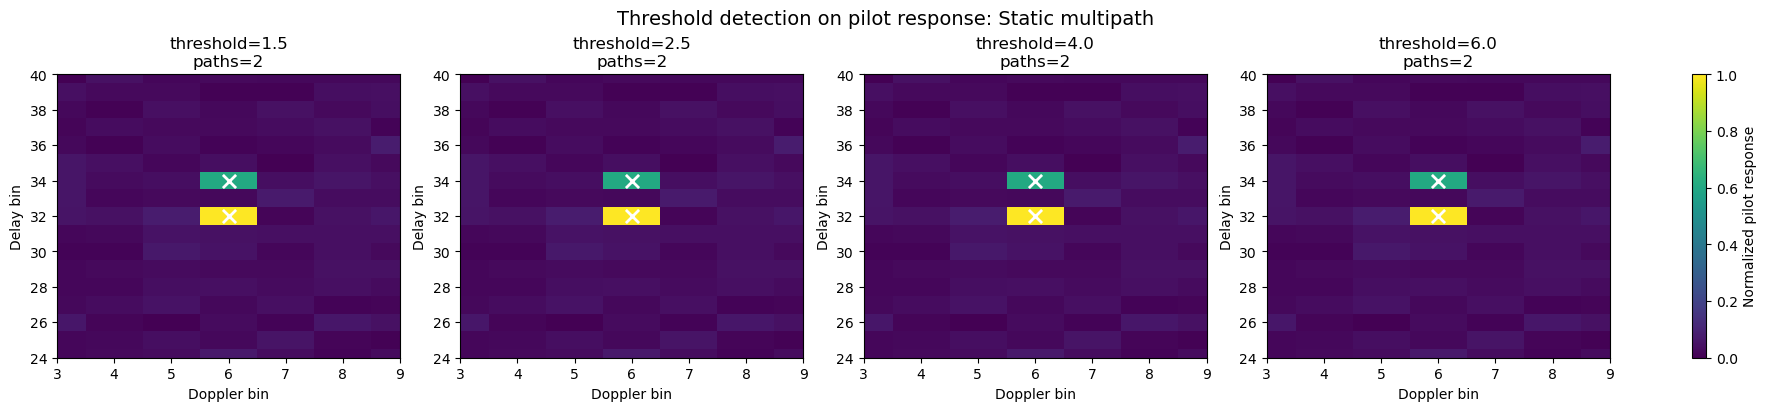

[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, 13562.10it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.024320
2  2  3  0.586660
6  1  0  0.006507
7  3  1  0.000633


30it [00:00, ?it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, 27521.68it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology


   x  y    score
0  0  2  1.02432
2  2  3  0.58666


30it [00:00, 29923.69it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology


   x  y    score
0  0  2  1.02432
2  2  3  0.58666


30it [00:00, 30023.65it/s]
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9940553172491491.
[08-06-2026 14:25:40] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]


   x  y    score
0  0  2  1.02432
2  2  3  0.58666


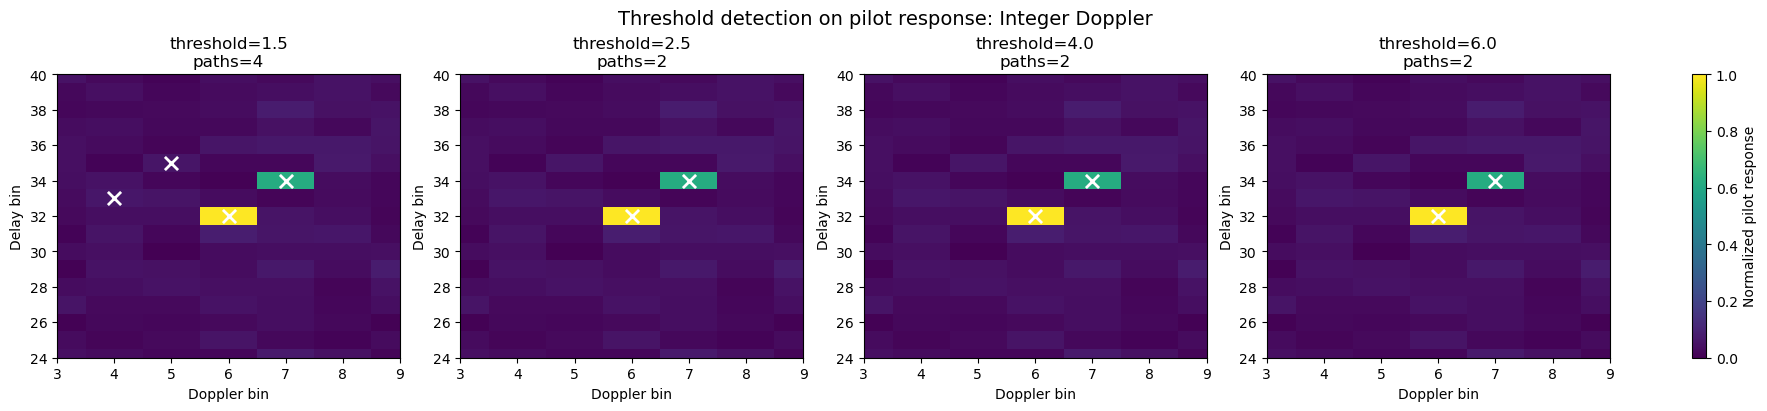

[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology
30it [00:00, 30059.51it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology
30it [00:00, 30037.99it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.


   x  y     score
0  0  2  1.042415
2  2  3  0.562404
3  3  1  0.311185
4  0  0  0.020035


[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.042415
2  2  3  0.562404
3  3  1  0.311185


30it [00:00, ?it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.042415
2  2  3  0.562404
3  3  1  0.311185


30it [00:00, 28346.28it/s]
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9908627420663834.
[08-06-2026 14:25:41] [findpeaks.stats] [INFO] Topology
30it [00:00, 30009.33it/s]


   x  y     score
0  0  2  1.042415
2  2  3  0.562404
3  3  1  0.311185


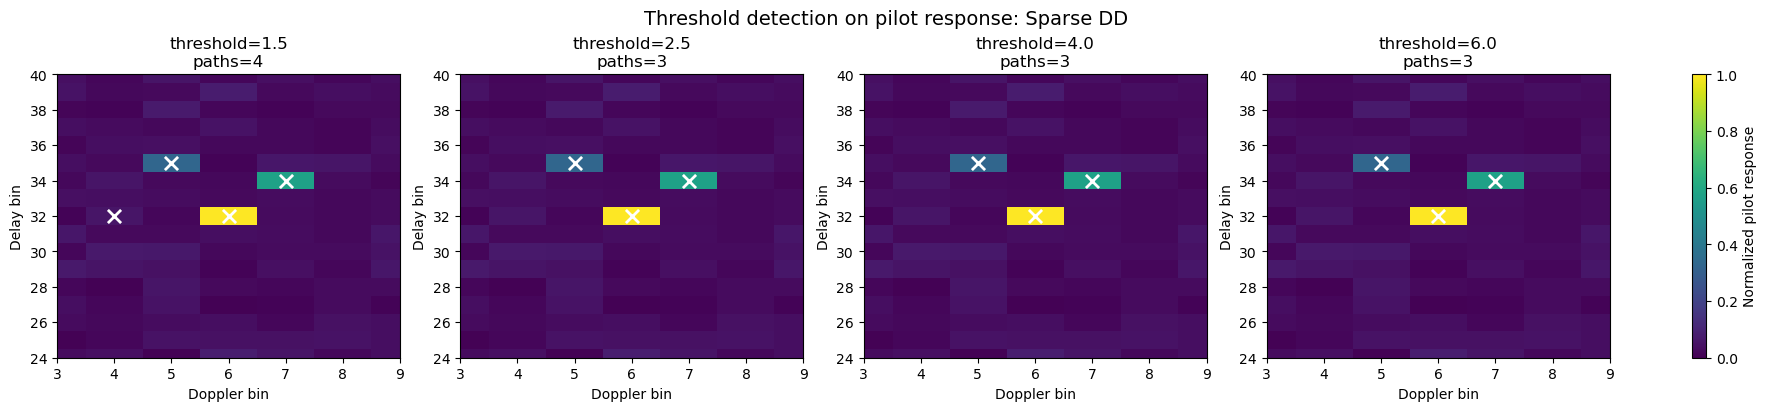

[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology
30it [00:00, 30145.93it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology
30it [00:00, 29873.96it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  0.983759
2  2  4  0.347446
3  3  1  0.148039
6  4  4  0.016405


30it [00:00, 54732.11it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  0.983759
2  2  4  0.347446
3  3  1  0.148039


30it [00:00, ?it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology
30it [00:00, 29697.69it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  0.983759
2  2  4  0.347446
3  3  1  0.148039


30it [00:00, 49190.43it/s]
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.9902400737628341.
[08-06-2026 14:25:42] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]


   x  y     score
0  0  2  0.983759
2  2  4  0.347446
3  3  1  0.148039


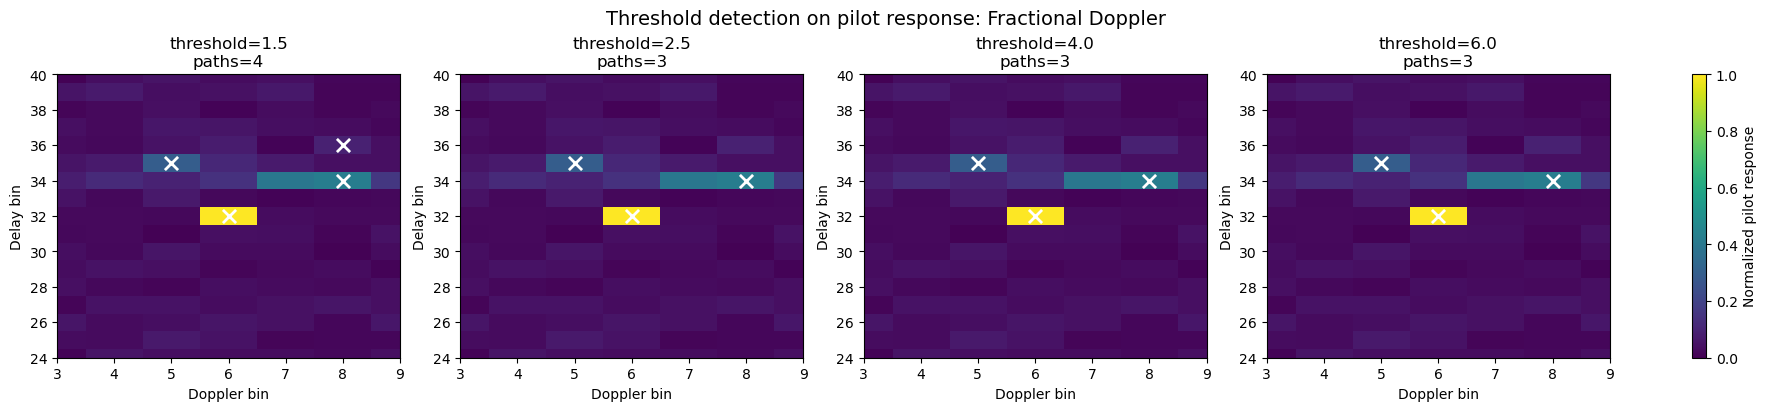

: 

: 

: 

: 

: 

In [ ]:
# Visualize how threshold factor changes detected taps.
for name, data in channel_data.items():
    fig, axes = plt.subplots(1, len(THRESHOLD_FACTORS), figsize=(4.4 * len(THRESHOLD_FACTORS), 4), constrained_layout=True)
    if len(THRESHOLD_FACTORS) == 1:
        axes = [axes]

    Y = data["y_dd_pilot"].numpy()[0, 0, 0]
    shown = np.abs(Y).T
    shown = shown / (np.max(shown) + 1e-12)

    for ax, threshold_factor in zip(axes, THRESHOLD_FACTORS):
        estimator = get_estimator(threshold_factor)
        g_hat, l_hat, k_hat, _ = estimator(data["y_dd_pilot"], no)

        im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
        doppler_margin = 3
        delay_margin = 8

        ax.set_xlim(
            pilot_k - doppler_margin,
            pilot_k + doppler_margin,
        )

        ax.set_ylim(
            pilot_l - delay_margin,
            pilot_l + delay_margin,
        )
        ax.set_title(f"threshold={threshold_factor}\npaths={len(l_hat)}")
        ax.set_xlabel("Doppler bin")
        ax.set_ylabel("Delay bin")

        # Estimator returns relative path taps l_hat, k_hat.
        # The estimator returns path locations relative to the pilot position.
        # Convert them back to absolute DD coordinates for plotting.
        det_delay = pilot_l + l_hat.numpy()
        det_doppler = pilot_k + k_hat.numpy()

        ax.scatter(
            det_doppler,
            det_delay,
            marker="x",
            s=90,
            linewidths=2.0,
            color="white",
        )

    fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized pilot response")
    fig.suptitle(f"Threshold detection on pilot response: {name}", fontsize=14)
    plt.show()

## 12. Reconstructing the Equalizer Channel from Estimated Paths

The estimated path parameters $\hat{g}_i$, $\hat{\ell}_i$, $\hat{k}_i$ are converted back into a delay-time channel array `gs_est` using `dd_paths_to_gs_via_h_time`. This function generates a synthetic CIR from the estimated integer path parameters, passes it through the same `cir_to_h_time` pipeline used for the true channel, and returns a `gs` array of the same shape as `gs_true`.

Three panels are shown for each channel case:

**`gs_true`:** the ground truth delay-time channel. Active taps appear as bright horizontal bands with the Doppler-induced phase ramp visible in the phase plot.

**`gs_est`:** the reconstructed delay-time channel from estimated paths. For integer Doppler channels this closely matches `gs_true` in both magnitude and phase. For fractional Doppler the integer-tap approximation introduces a systematic phase error that grows across the frame duration.

**Error $|$`gs_true` $-$ `gs_est`$|$:** the reconstruction error. Small for integer Doppler cases (noise-limited), large for fractional Doppler (model-mismatch limited). The printed NMSE values summarize the estimation quality for each case.

For the integer Doppler cases the NMSE is limited by the SNR -- better SNR would reduce it. For the fractional Doppler case the NMSE is limited by the mismatch between the true continuous Doppler value and the integer-tap model -- better SNR would not reduce it.

In [ ]:
for name, data in channel_data.items():
    g_hat = data["g_hat"]
    l_hat = data["l_hat"]
    k_hat = data["k_hat"]

    # Convert the detected DD paths into the delay-time representation required by BlockLMMSEEqualizer.
    gs_est = dd_paths_to_gs_via_h_time(
        g_i=g_hat,
        l_i=l_hat,
        k_i=tf.cast(k_hat, tf.float32),
        bandwidth=rg.bandwidth,
        num_time_samples=num_time_samples,
        batch_size=BATCH_SIZE,
        l_min=CHANNEL_L_MIN,
        l_max=CHANNEL_L_MAX,
        normalize=CHANNEL_NORMALIZE,
    )

    data["gs_est"] = gs_est

    # Pad/crop to the same delay dimension for error plotting.
    # Compare the reconstructed channel against the true equalizer channel.
    true = data["gs_true"].numpy()
    est = gs_est.numpy()

    L = max(true.shape[0], est.shape[0])
    # Pad true and estimated gs to the same delay dimension before computing the error.
    true_pad = np.zeros((L, true.shape[1]), dtype=np.complex64)
    est_pad = np.zeros((L, est.shape[1]), dtype=np.complex64)
    true_pad[:true.shape[0], :true.shape[1]] = true
    est_pad[:est.shape[0], :est.shape[1]] = est

    data["gs_true_padded"] = true_pad
    data["gs_est_padded"] = est_pad
    data["gs_error"] = true_pad - est_pad

    nmse = np.sum(np.abs(true_pad - est_pad) ** 2) / (np.sum(np.abs(true_pad) ** 2) + 1e-12)
    data["gs_nmse"] = nmse
    print(f"{name:20s} gs NMSE = {nmse:.4e}")

Static multipath     gs NMSE = 2.9163e-04
Integer Doppler      gs NMSE = 1.9074e-03
Sparse DD            gs NMSE = 2.6788e-03
Fractional Doppler   gs NMSE = 1.7214e-01


: 

: 

: 

: 

: 

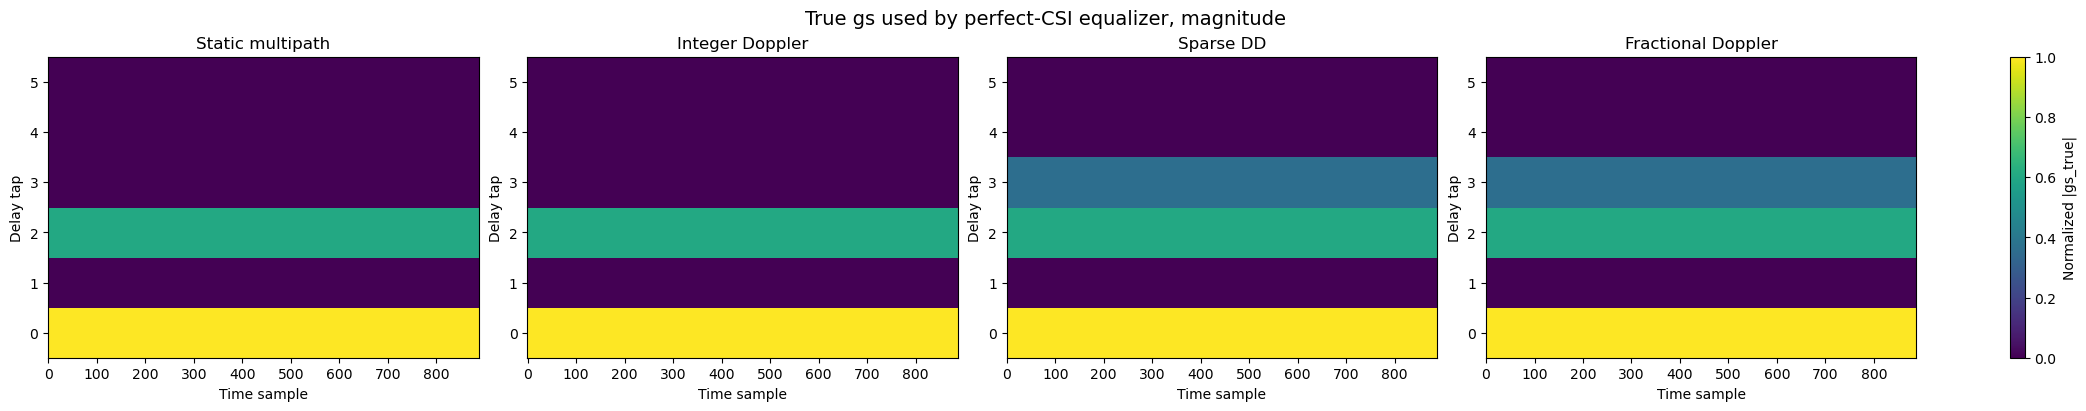

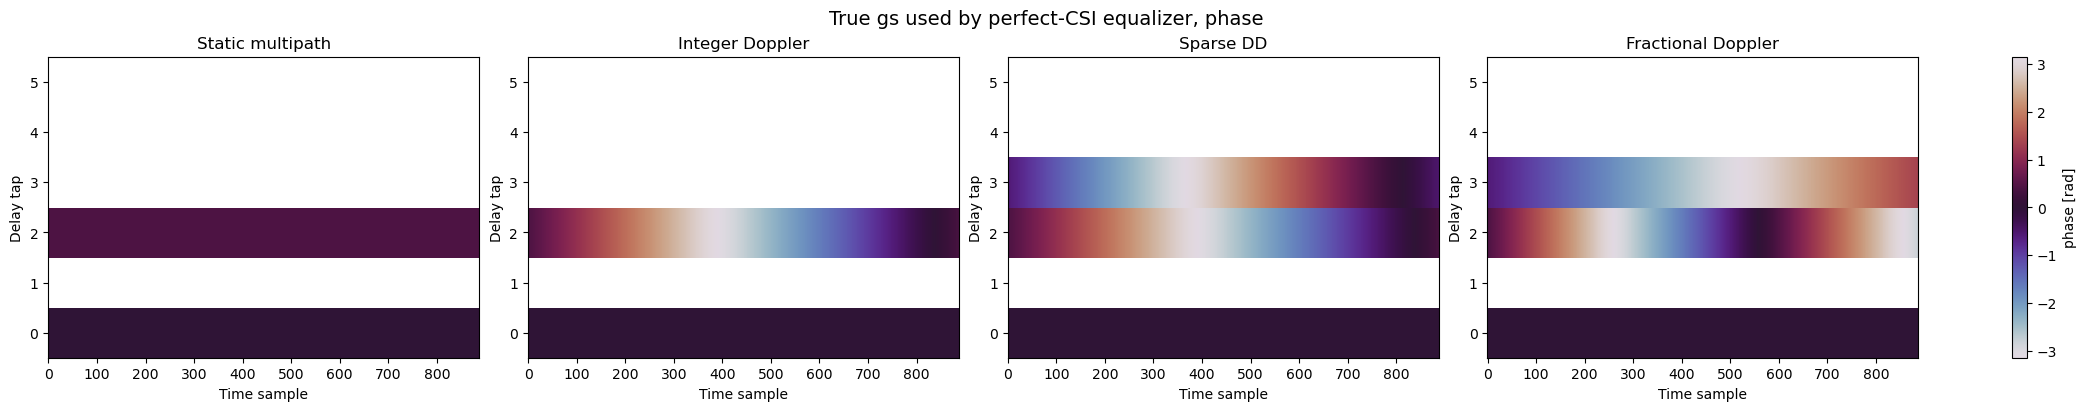

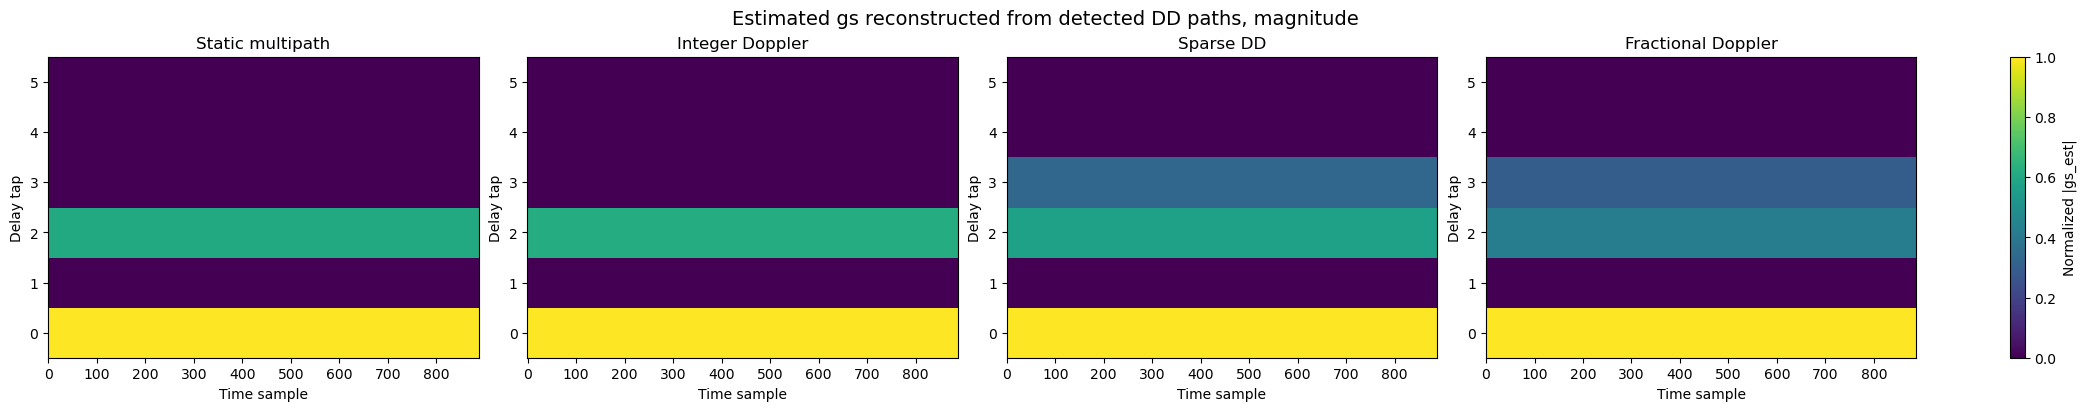

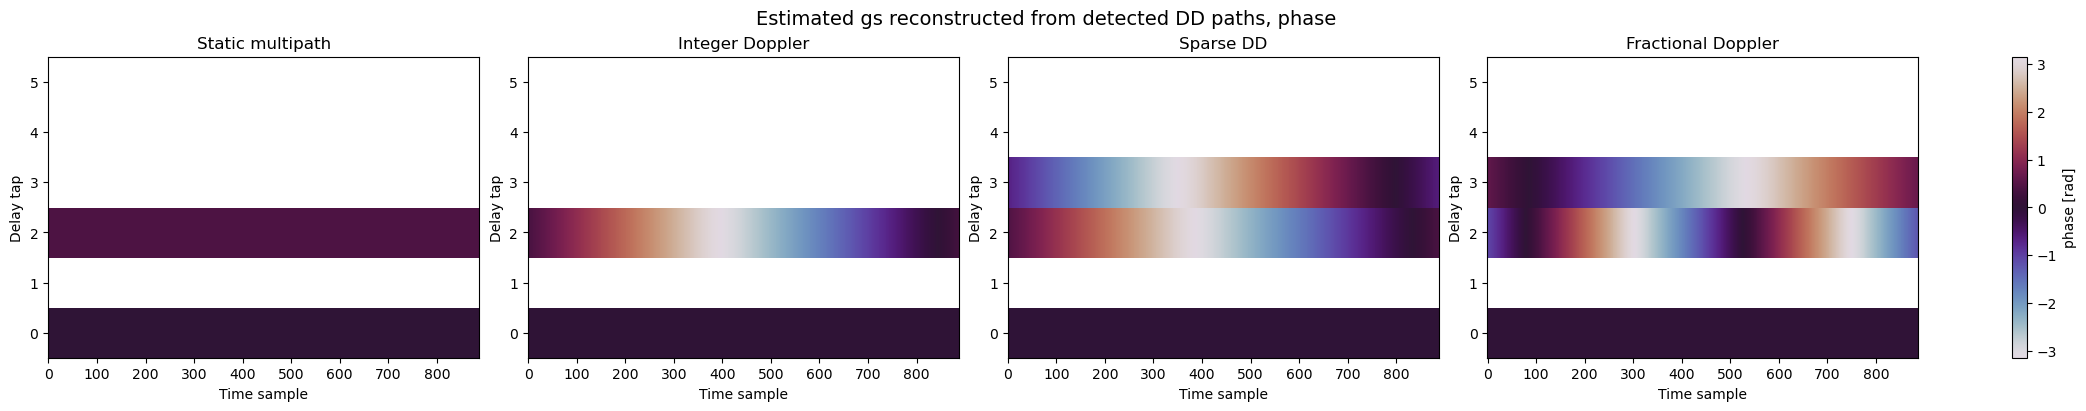

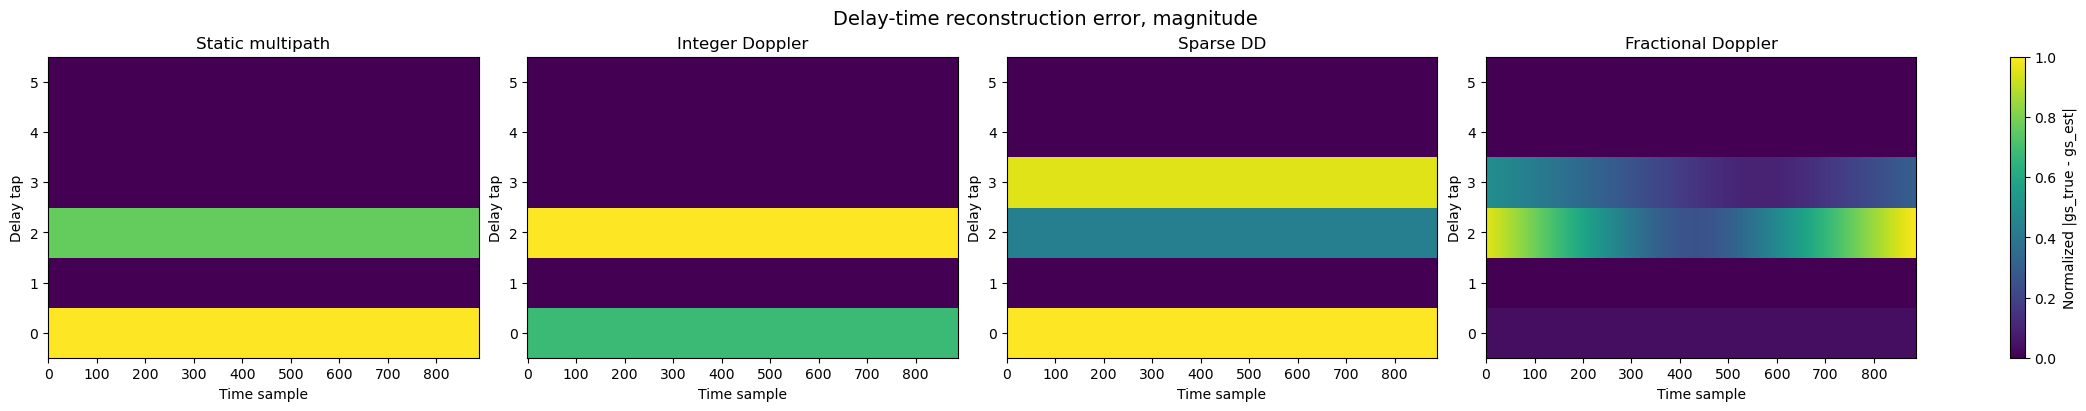

: 

: 

: 

: 

: 

In [ ]:
for key, title, colorbar_label in [
    ("gs_true_padded", "True gs used by perfect-CSI equalizer", "Normalized |gs_true|"),
    ("gs_est_padded", "Estimated gs reconstructed from detected DD paths", "Normalized |gs_est|"),
    ("gs_error", "Delay-time reconstruction error", "Normalized |gs_true - gs_est|"),
]:
    fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
    if len(channel_data) == 1:
        axes = [axes]

    for ax, (name, data) in zip(axes, channel_data.items()):
        Z = data[key]
        shown = np.abs(Z)
        shown = shown / (np.max(shown) + 1e-12)
        im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(name)
        ax.set_xlabel("Time sample")
        ax.set_ylabel("Delay tap")
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    fig.colorbar(im, ax=np.ravel(axes).tolist(), label=colorbar_label)
    fig.suptitle(title + ", magnitude", fontsize=14)
    plt.show()

    if key != "gs_error":
        fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
        if len(channel_data) == 1:
            axes = [axes]

        for ax, (name, data) in zip(axes, channel_data.items()):
            Z = data[key]
            phase = masked_phase(Z)
            im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi, interpolation="nearest")
            ax.set_title(name)
            ax.set_xlabel("Time sample")
            ax.set_ylabel("Delay tap")
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))

        fig.colorbar(im, ax=np.ravel(axes).tolist(), label="phase [rad]")
        fig.suptitle(title + ", phase", fontsize=14)
        plt.show()

## 13. Estimated-CSI Block LMMSE Equalization

The same block LMMSE equalization as in Section 8, now using `gs_est` reconstructed from the embedded pilot estimator instead of `gs_true`.

The three-row constellation panel compares:

- **Row 1:** no equalization
- **Row 2:** perfect-CSI LMMSE (using `gs_true`)
- **Row 3:** estimated-CSI LMMSE (using `gs_est` from the pilot estimator)

For the static multipath, integer Doppler, and sparse DD cases the estimated-CSI constellations are close to the perfect-CSI ones -- the QAM clusters are recovered with nearly the same spread. The gap reflects the channel NMSE from Section 12.

For the fractional Doppler case the estimated-CSI equalization is noticeably worse than perfect CSI: the clusters are wider and the QAM points harder to distinguish. This is the direct consequence of the channel NMSE driven by model mismatch rather than noise. Unlike the integer Doppler cases, this gap cannot be closed by increasing SNR -- it requires a better channel model that handles fractional Doppler explicitly.

In [ ]:
for name, data in channel_data.items():
    # Equalization using the reconstructed channel from the estimator.
    y_time_est_lmmse = block_lmmse(
        data["y_time_noisy"],
        data["gs_est"],
        no,
    )

    y_tf_est_lmmse = ofdm_demodulator_no_cp(y_time_est_lmmse)
    y_dd_est_lmmse = otfs_demodulator(y_tf_est_lmmse)
    x_hat_est_lmmse = rg_demapper(y_dd_est_lmmse)

    data["y_time_est_lmmse"] = y_time_est_lmmse
    data["y_tf_est_lmmse"] = y_tf_est_lmmse
    data["y_dd_est_lmmse"] = y_dd_est_lmmse
    data["x_hat_est_lmmse"] = x_hat_est_lmmse

print("Estimated-CSI LMMSE equalization completed.")

Estimated-CSI LMMSE equalization completed.


: 

: 

: 

: 

: 

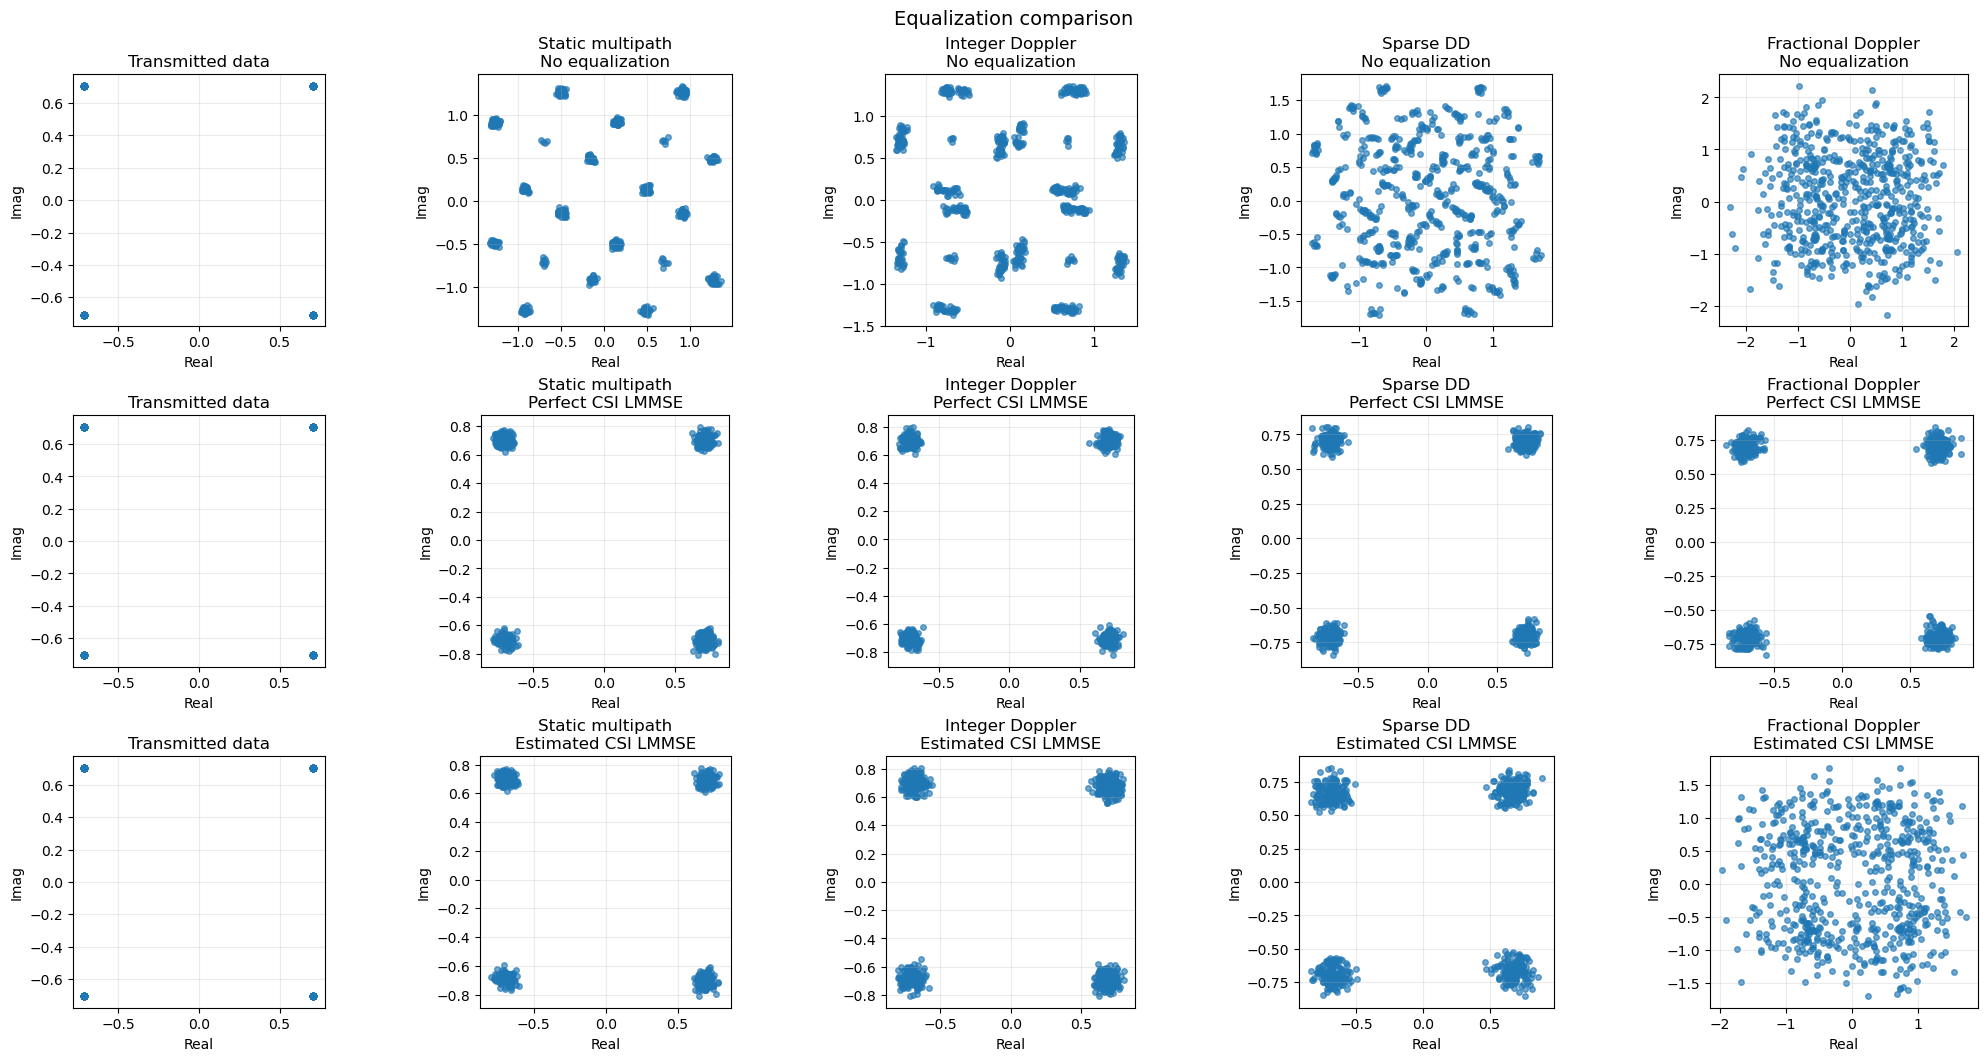

: 

: 

: 

: 

: 

In [ ]:
fig, axes = plt.subplots(
    3,
    len(channel_data) + 1,
    figsize=(4.1 * (len(channel_data) + 1), 10.5),
    constrained_layout=True,
)

for row, row_title in enumerate(["Reference", "No EQ", "Perfect CSI", "Estimated CSI"][:3]):
    pass

for row in range(3):
    axes[row, 0].scatter(np.real(x_symbols), np.imag(x_symbols), s=20, alpha=0.8)
    axes[row, 0].set_title("Transmitted data")
    axes[row, 0].set_xlabel("Real")
    axes[row, 0].set_ylabel("Imag")
    axes[row, 0].grid(True, alpha=0.25)
    axes[row, 0].set_aspect("equal", adjustable="box")

for col, (name, data) in enumerate(channel_data.items(), start=1):
    y_no_eq = data["x_hat_no_eq"].numpy()[0, 0, 0].reshape(-1)
    y_perfect = data["x_hat_lmmse"].numpy()[0, 0, 0].reshape(-1)
    y_est = data["x_hat_est_lmmse"].numpy()[0, 0, 0].reshape(-1)

    plot_items = [
        (y_no_eq, "No equalization"),
        (y_perfect, "Perfect CSI LMMSE"),
        (y_est, "Estimated CSI LMMSE"),
    ]

    for row, (symbols, subtitle) in enumerate(plot_items):
        axes[row, col].scatter(np.real(symbols), np.imag(symbols), s=16, alpha=0.65)
        axes[row, col].set_title(f"{name}\n{subtitle}")
        axes[row, col].set_xlabel("Real")
        axes[row, col].set_ylabel("Imag")
        axes[row, col].grid(True, alpha=0.25)
        axes[row, col].set_aspect("equal", adjustable="box")

fig.suptitle("Equalization comparison", fontsize=14)
plt.show()

## 14. Threshold Sweep: NMSE and Detected Path Count

The threshold factor is swept over a range and for each value the path detection is re-run, the channel is reconstructed from the detected paths, and the NMSE against `gs_true` is recorded alongside the detected path count.

**NMSE vs. threshold:** at very low thresholds, noise peaks are detected as spurious paths. The extra paths add wrong-gain contributions to `gs_est`, raising NMSE. As the threshold increases the NMSE falls towards a minimum where the real paths are detected and noise peaks are mostly rejected. At very high thresholds real paths begin to be missed and NMSE rises again.

The fractional Doppler curve sits at a higher NMSE floor across the entire sweep. This floor is set by model mismatch, not by noise or threshold choice: even at the optimal threshold the integer-tap reconstruction is an approximation of the true fractional-tap channel.

**Path count vs. threshold:** at low thresholds many spurious paths are detected. As the threshold increases the count falls towards the true number of paths in each channel case. At very high thresholds the count drops below the true number as real paths are missed.

The two curves together characterize the operating region for the `DEFAULT_THRESHOLD_FACTOR`: it should sit in the range where real paths are all detected and spurious detections are rare, while remaining robust to variation in SNR across different operating conditions.

In [ ]:
# Explore the estimator sensitivity to the detection threshold.
threshold_sweep = np.linspace(0.5, 8.0, 16)

for name, data in channel_data.items():
    nmse_values = []
    path_counts = []

    true = data["gs_true"].numpy()

    for threshold_factor in threshold_sweep:
        estimator = get_estimator(float(threshold_factor))
        g_hat, l_hat, k_hat, _ = estimator(data["y_dd_pilot"], no)

        # Reconstruct gs for each threshold so NMSE can be compared consistently.
        gs_est = dd_paths_to_gs_via_h_time(
            g_i=g_hat,
            l_i=l_hat,
            k_i=tf.cast(k_hat, tf.float32),
            bandwidth=rg.bandwidth,
            num_time_samples=num_time_samples,
            batch_size=BATCH_SIZE,
            l_min=CHANNEL_L_MIN,
            l_max=CHANNEL_L_MAX,
            normalize=CHANNEL_NORMALIZE,
        ).numpy()

        L = max(true.shape[0], gs_est.shape[0])
        true_pad = np.zeros((L, true.shape[1]), dtype=np.complex64)
        est_pad = np.zeros((L, gs_est.shape[1]), dtype=np.complex64)
        true_pad[:true.shape[0], :true.shape[1]] = true
        est_pad[:gs_est.shape[0], :gs_est.shape[1]] = gs_est

        nmse = np.sum(np.abs(true_pad - est_pad) ** 2) / (np.sum(np.abs(true_pad) ** 2) + 1e-12)
        # Reconstruction quality of gs at this threshold.
        nmse_values.append(nmse)
        # Number of DD paths detected at this threshold.
        path_counts.append(len(l_hat))

    data["threshold_sweep"] = threshold_sweep
    data["nmse_sweep"] = np.array(nmse_values)
    data["path_count_sweep"] = np.array(path_counts)

[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology
30it [00:00, 7473.81it/s]
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135
3  5  4  0.018259
7  3  0  0.004947


30it [00:00, 30254.66it/s]
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135
3  5  4  0.018259
7  3  0  0.004947


30it [00:00, 29803.20it/s]
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology
30it [00:00, ?it/s]
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at -0.996504073496908.
[08-06-2026 14:25:46] [findpeaks.stats] [INFO] Topology


   x  y     score
0  0  2  1.012965
2  2  2  0.544135


... (124 outputs left out)

: 

: 

: 

: 

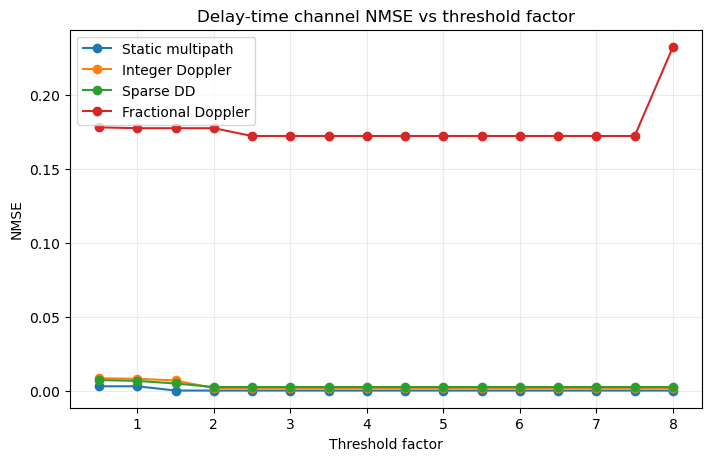

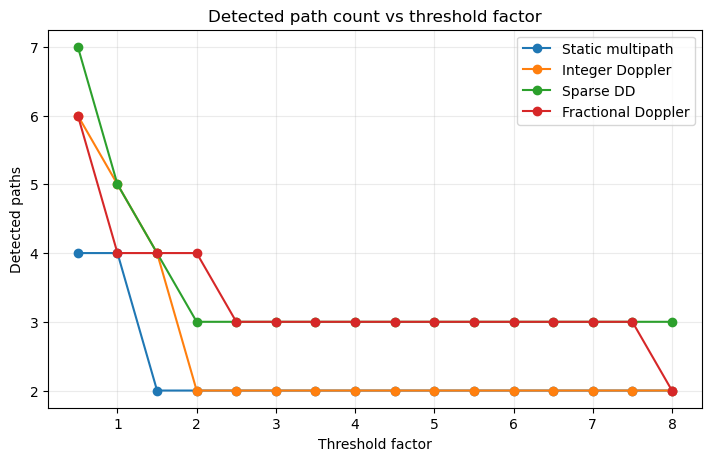

: 

: 

: 

: 

: 

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)

for name, data in channel_data.items():
    ax.plot(
        data["threshold_sweep"],
        data["nmse_sweep"],
        marker="o",
        label=name,
    )

ax.set_title("Delay-time channel NMSE vs threshold factor")
ax.set_xlabel("Threshold factor")
ax.set_ylabel("NMSE")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)

for name, data in channel_data.items():
    ax.plot(
        data["threshold_sweep"],
        data["path_count_sweep"],
        marker="o",
        label=name,
    )

ax.set_title("Detected path count vs threshold factor")
ax.set_xlabel("Threshold factor")
ax.set_ylabel("Detected paths")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

## 15. Summary

This notebook completed the full receiver chain from received waveform to recovered QAM symbols.

The key implementation points are:

- **`gs` is the central object.** The equalizer uses the delay-time channel `gs`, not the raw CIR tensor or the DD path list. `h_time_to_gs` and `dd_paths_to_gs_via_h_time` are the two conversion paths: one from the true channel, one from the estimated path parameters.
- **`BlockLMMSEEqualizer` constructs one $M \times M$ matrix per CP-OFDM block.** The matrix is built from `gs` evaluated at the time index of that block. For static multipath it is approximately circulant; for Doppler channels it deviates increasingly with Doppler magnitude.
- **Integer Doppler estimation is near noise-limited.** The embedded pilot estimator recovers the correct delay and Doppler positions for integer-tap channels, and the resulting `gs_est` closely matches `gs_true`. Estimated-CSI equalization performs close to perfect-CSI equalization.
- **Fractional Doppler estimation is model-mismatch limited.** The integer-tap assumption introduces a systematic reconstruction error in `gs_est` that grows across the frame and does not improve with SNR. The performance gap between estimated-CSI and perfect-CSI equalization is irreducible without a model that handles fractional Doppler explicitly.
- **Threshold choice is a design parameter.** The sweep in Section 14 characterizes the optimal operating region empirically: low enough to detect all real paths, high enough to suppress noise peaks.